# Détection d'anomalies sans étiquettes dans le trafic réseau
### Détecteurs entraînés sur trafic normal uniquement, évalués sur UNSW-NB15 (Projet 6)

**Binôme :** Farah Chebbi, Firas Ben Hmida &nbsp;|&nbsp; **Date :** 03/11/2026

## Résumé
**Question.** Peut-on repérer des intrusions réseau en apprenant uniquement ce qu'est le trafic normal, sans aucune étiquette d'attaque à l'entraînement ? Avec quelle précision, quelle charge d'alertes, et quelle robustesse si l'entraînement est contaminé ?

**Démarche.** Nettoyage rigoureux (doublons, fuites entre fichiers), découpage entraînement / validation / test, baseline statistique, puis cinq détecteurs (Isolation Forest, One-Class SVM, DBSCAN, kNN, autoencodeur) réglés sur la validation, seuil d'alerte fixé **sans étiquettes de test**, évaluation unique sur le test, analyse par famille d'attaque, charge d'alertes, contamination de l'entraînement, borne supérieure supervisée, analyse critique des familles difficiles et combinaison non supervisé + supervisé.

## Plan
1. Configuration et données
2. Nettoyage, découpage sans fuite, préparation
3. Baseline (score z, Mahalanobis)
4. Détecteurs et réglage sur la validation (dont l'autoencodeur)
5. Évaluation sur le test (une seule fois) : résultats, familles, charge d'alertes, métriques opérationnelles, intervalles de confiance, calibration du seuil
6. Robustesse : contamination de l'entraînement et entraînement robuste (élagage)
7. Borne supérieure supervisée
8. Analyse critique des familles difficiles
9. Combinaison : détecteur non supervisé puis classifieur supervisé
10. Conclusions et limites
- **Annexes (analyses supplémentaires, non requises)** : A. sélection de variables ; B. ensemble de détecteurs ; C. explicabilité ; D. score de risque ; E. évaluation sur attaques synthétiques complémentaires.

## Reproductibilité
- Graine fixée (`SEED = 42`) pour tous les tirages et modèles ; versions des bibliothèques affichées à la section 1.
- Le notebook s'exécute de haut en bas dans Google Colab (environ 40 à 60 minutes avec les réglages par défaut ; les sections 4 (autoencodeur), 6 et 7 sont les plus longues).
- Données : UNSW-NB15 (fichiers `UNSW_NB15_training-set.csv` et `UNSW_NB15_testing-set.csv`, Kaggle `mrwellsdavid/unsw-nb15`), à placer dans `archive.zip` sous `projet6/data/` du Drive.

## Règle d'évaluation
Le **test n'est utilisé qu'après figement des hyperparamètres et des seuils** (sections 5 à 9). Les seuils sont toujours fixés sur le trafic **normal de validation**, jamais avec les étiquettes du test. Les annexes relisent le test à titre d'analyse supplémentaire et ne modifient aucun réglage.

## 1. Configuration et données

In [1]:
import os, time, json, itertools, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

# --- Drive (Colab) : le dossier projet6/data doit contenir archive.zip (Kaggle UNSW-NB15) ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/projet6/data/"
except ImportError:                      # exécution hors Colab
    DATA_DIR = os.environ.get("UNSW_DATA_DIR", "data/")
BASE = DATA_DIR + "UNSW/"
os.makedirs(BASE, exist_ok=True)

# --- Extraction des deux seuls fichiers utiles (les 4 gros fichiers du zip ne servent pas) ---
FICHIERS = ["UNSW_NB15_training-set.csv", "UNSW_NB15_testing-set.csv"]
if not all(os.path.exists(BASE + f) for f in FICHIERS):
    with zipfile.ZipFile(DATA_DIR + "archive.zip") as z:
        for f in FICHIERS:
            with z.open(f) as src, open(BASE + f, "wb") as dst:
                dst.write(src.read())
print("Fichiers prêts :", [f for f in FICHIERS if os.path.exists(BASE + f)])

import sklearn
print("Versions : numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fichiers prêts : ['UNSW_NB15_training-set.csv', 'UNSW_NB15_testing-set.csv']
Versions : numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


## 2. Nettoyage, découpage sans fuite, préparation

**Choix et justifications**
- Colonne `id` supprimée : simple numéro de ligne, sans signification réseau.
- Doublons supprimés : ce jeu en contient beaucoup, ce qui gonfle artificiellement les scores. On retire aussi du test les flux **identiques** à un flux du training (sinon fuite).
- **Entraînement** : 70 % des flux *normaux* du fichier training, aucune attaque. **Validation** : les 30 % restants des normaux + les attaques du fichier training (réglage des hyperparamètres et du seuil). **Test** : le fichier testing, utilisé une seule fois.
- Variables numériques : log signé puis standardisation ; variables catégorielles : one-hot. Tout est **appris sur l'entraînement seul**.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

tr = pd.read_csv(BASE + FICHIERS[0]); te = pd.read_csv(BASE + FICHIERS[1])
tr = tr.drop(columns=["id"]); te = te.drop(columns=["id"])
tr = tr.replace([np.inf, -np.inf], np.nan); te = te.replace([np.inf, -np.inf], np.nan)
print("Valeurs manquantes (train, test) :", tr.isna().sum().sum(), te.isna().sum().sum())
tr = tr.dropna().copy(); te = te.dropna().copy()

feat = [c for c in tr.columns if c not in ("attack_cat", "label")]
n_tr, n_te = len(tr), len(te)
tr = tr.drop_duplicates(subset=feat + ["label"]).copy()
te = te.drop_duplicates(subset=feat + ["label"]).copy()
print("Doublons internes supprimés : training", n_tr - len(tr), "| testing", n_te - len(te))

cle = tr[feat].drop_duplicates().assign(_dup=1)          # flux du test identiques au training
m = te.merge(cle, on=feat, how="left")
print("Flux du test identiques au training (supprimés) :", int(m["_dup"].notna().sum()))
te = m[m["_dup"].isna()].drop(columns="_dup").reset_index(drop=True)

# ---- Découpage ----
normal = tr[tr["label"] == 0]; attaques_tr = tr[tr["label"] == 1]
train, val_norm = train_test_split(normal, test_size=0.30, random_state=SEED)
val = pd.concat([val_norm, attaques_tr]).sample(frac=1, random_state=SEED).reset_index(drop=True)
train = train.reset_index(drop=True); test = te
assert train["label"].sum() == 0, "des attaques dans l'entraînement !"

# ---- Préparation apprise sur train uniquement ----
cat_cols = ["proto", "service", "state"]
num_cols = [c for c in feat if c not in cat_cols]
def slog(x): return np.sign(x) * np.log1p(np.abs(x))
Xnum_tr = slog(train[num_cols].values.astype(float))
keep = Xnum_tr.std(axis=0) > 0
scaler = StandardScaler().fit(Xnum_tr[:, keep])
enc = OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=10, sparse_output=False).fit(train[cat_cols])
def prep(d):
    num = scaler.transform(slog(d[num_cols].values.astype(float))[:, keep])
    return np.hstack([num, enc.transform(d[cat_cols])]).astype("float32")

Xtr, Xva, Xte = prep(train), prep(val), prep(test)
yva, yte = val["label"].values, test["label"].values
fam_va = val["attack_cat"].values.astype(str); fam_te = test["attack_cat"].values.astype(str)
noms_var = np.array([c for c, k in zip(num_cols, keep) if k] + list(enc.get_feature_names_out(cat_cols)))

print(f"\nTrain {Xtr.shape} (0 attaque) | Val {Xva.shape} ({yva.mean():.1%} attaques) | Test {Xte.shape} ({yte.mean():.1%} attaques)")
print("PR-AUC d'un détecteur au hasard : val =", round(yva.mean(), 3), "| test =", round(yte.mean(), 3))
print("Familles val :", pd.Series(fam_va).value_counts().to_dict())
print("Familles test:", pd.Series(fam_te).value_counts().to_dict())
np.savez_compressed(BASE + "prepared.npz", Xtr=Xtr, Xva=Xva, yva=yva, Xte=Xte, yte=yte,
                    fam_va=fam_va, fam_te=fam_te, noms=noms_var)

Valeurs manquantes (train, test) : 0 0
Doublons internes supprimés : training 28380 | testing 74072
Flux du test identiques au training (supprimés) : 1400

Train (23944, 58) (0 attaque) | Val (30008, 58) (65.8% attaques) | Test (99869, 58) (48.4% attaques)
PR-AUC d'un détecteur au hasard : val = 0.658 | test = 0.484
Familles val : {'Normal': 10262, 'Exploits': 7126, 'Fuzzers': 4394, 'Generic': 3640, 'Reconnaissance': 2469, 'DoS': 1315, 'Shellcode': 377, 'Analysis': 312, 'Backdoor': 70, 'Worms': 43}
Familles test: {'Normal': 51496, 'Exploits': 18699, 'Fuzzers': 14759, 'Reconnaissance': 6195, 'Generic': 3686, 'DoS': 2989, 'Shellcode': 1072, 'Analysis': 498, 'Backdoor': 355, 'Worms': 120}


In [3]:
# (Facultatif) Après une déconnexion Colab, relancer UNIQUEMENT cette cellule + la cellule d'imports de la section 1
# permet de recharger les données préparées sans refaire le nettoyage.
D = np.load(BASE + "prepared.npz", allow_pickle=True)
Xtr, Xva, yva, Xte, yte = D["Xtr"], D["Xva"], D["yva"], D["Xte"], D["yte"]
fam_va, fam_te, noms_var = D["fam_va"], D["fam_te"], D["noms"]
normal_va, normal_te = (yva == 0), (yte == 0)
print("Rechargé :", Xtr.shape, Xva.shape, Xte.shape)

Rechargé : (23944, 58) (30008, 58) (99869, 58)


## 3. Baseline

Deux détecteurs simples, ajustés sur le trafic normal :
- **Score z maximal** : plus grand écart (en écarts-types) d'une variable au trafic normal.
- **Distance de Mahalanobis** (covariance régularisée de Ledoit-Wolf) : distance globale qui tient compte des corrélations.

Le **seuil d'alerte** est toujours fixé **sans étiquette d'attaque** : c'est le quantile du score sur le trafic *normal* de validation qui laisse passer un taux de faux positifs cible (1, 5 ou 10 %). La PR-AUC est comparée à la proportion d'attaques (détecteur au hasard).

PR-AUC du hasard (validation) : 0.658

    detecteur  PR_AUC  ROC_AUC  FP_cible  precision  rappel    F1
Score z (max)   0.762    0.587      0.01      0.943   0.079 0.147
Score z (max)   0.762    0.587      0.05      0.871   0.175 0.292
Score z (max)   0.762    0.587      0.10      0.826   0.239 0.371
  Mahalanobis   0.853    0.738      0.01      0.966   0.149 0.258
  Mahalanobis   0.853    0.738      0.05      0.921   0.302 0.454
  Mahalanobis   0.853    0.738      0.10      0.907   0.507 0.650


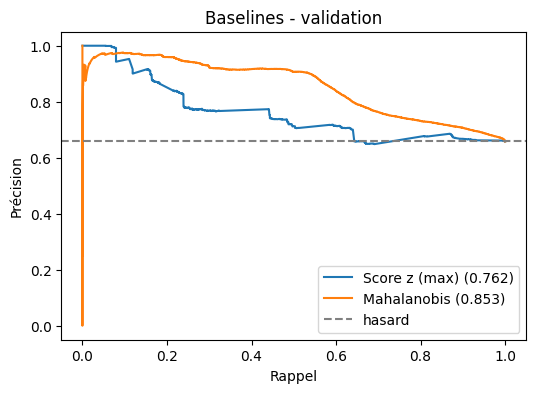

In [4]:
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

is_num = np.array([not any(n.startswith(p + "_") for p in ("proto", "service", "state")) for n in noms_var])
lw = LedoitWolf().fit(Xtr)
base_scores = {"Score z (max)": np.abs(Xva[:, is_num]).max(axis=1), "Mahalanobis": lw.mahalanobis(Xva)}

print(f"PR-AUC du hasard (validation) : {yva.mean():.3f}\n")
lignes = []
for nom, s in base_scores.items():
    for fpr in (0.01, 0.05, 0.10):
        seuil = np.quantile(s[normal_va], 1 - fpr); pred = (s > seuil).astype(int)
        lignes.append(dict(detecteur=nom, PR_AUC=round(average_precision_score(yva, s), 3),
                           ROC_AUC=round(roc_auc_score(yva, s), 3), FP_cible=fpr,
                           precision=round(precision_score(yva, pred, zero_division=0), 3),
                           rappel=round(recall_score(yva, pred), 3), F1=round(f1_score(yva, pred), 3)))
print(pd.DataFrame(lignes).to_string(index=False))

plt.figure(figsize=(6, 4))
for nom, s in base_scores.items():
    p, r, _ = precision_recall_curve(yva, s); plt.plot(r, p, label=f"{nom} ({average_precision_score(yva, s):.3f})")
plt.axhline(yva.mean(), ls="--", c="gray", label="hasard")
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.title("Baselines - validation"); plt.legend(); plt.show()

## 4. Détecteurs et réglage sur la validation

| Détecteur | Idée |
|---|---|
| **Isolation Forest** | isole chaque flux par des découpages aléatoires ; un flux atypique est isolé vite |
| **One-Class SVM** (noyau RBF) | frontière autour du trafic normal ; score = distance à l'intérieur de cette frontière |
| **DBSCAN** | zones denses de trafic normal. DBSCAN n'ayant pas de `predict`, le score d'un flux est sa **distance au point central (core point) le plus proche**. Au-delà de `eps`, DBSCAN le classerait comme bruit |
| **kNN (témoin)** | distance au k-ième voisin normal, pour vérifier si DBSCAN apporte autre chose qu'un score de voisinage |
| **Autoencodeur** (extension) | réseau de neurones 58-32-*b*-32-58 entraîné à **reconstruire** le trafic normal à travers un goulot de *b* neurones ; score = erreur quadratique moyenne de reconstruction. Un flux mal reconstruit s'écarte de la structure apprise du normal |

L'autoencodeur diffère des autres : il apprend une **représentation compressée non linéaire** du normal, là où les autres mesurent une densité, une distance ou une profondeur d'isolement.

Tous les détecteurs sont entraînés sur **le même échantillon** (tous les flux normaux d'entraînement). Les hyperparamètres sont choisis par PR-AUC sur la **validation**, jamais sur le test ; les grilles ont été élargies jusqu'à ce que les optimums ne soient plus au bord.

`RETUNE = False` reprend les hyperparamètres déjà trouvés pour Isolation Forest, One-Class SVM, DBSCAN et kNN (`True` : environ 10 minutes de plus). L'autoencodeur est **toujours réglé ici** (`RETUNE_AE = True`) : environ 3 à 6 minutes.

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor

RETUNE = False
RETUNE_AE = True
PARAMS = {"Mahalanobis": {},
          "Isolation Forest": {"n_estimators": 300, "max_samples": 23944, "max_features": 0.7},
          "DBSCAN": {"eps": 5.994473602771761, "min_samples": 5},
          "One-Class SVM": {"nu": 0.05, "gamma": 1.0},
          "kNN": {"k": 1},
          "Autoencodeur": {"bottleneck": 8, "alpha": 1e-3}}      # valeurs initiales, remplacées après réglage

def build(nom, X, params=None):
    "Ajuste le détecteur sur X (trafic normal) et renvoie une fonction de score (grand = suspect)."
    p = (params or PARAMS)[nom]
    if nom == "Mahalanobis":
        m = LedoitWolf().fit(X);                                         return lambda Z: m.mahalanobis(Z)
    if nom == "Isolation Forest":
        m = IsolationForest(random_state=SEED, n_jobs=-1, **p).fit(X);   return lambda Z: -m.score_samples(Z)
    if nom == "One-Class SVM":
        m = OneClassSVM(kernel="rbf", **p).fit(X);                       return lambda Z: -m.decision_function(Z)
    if nom == "DBSCAN":
        db = DBSCAN(n_jobs=-1, **p).fit(X)
        if len(db.core_sample_indices_) == 0: raise ValueError("aucun point central")
        nn = NearestNeighbors(n_neighbors=1).fit(X[db.core_sample_indices_])
        return lambda Z: nn.kneighbors(Z)[0][:, 0]
    if nom == "kNN":
        nn = NearestNeighbors(n_neighbors=p["k"]).fit(X);                return lambda Z: nn.kneighbors(Z)[0][:, -1]
    if nom == "Autoencodeur":
        m = MLPRegressor(hidden_layer_sizes=(32, int(p["bottleneck"]), 32), alpha=p["alpha"], max_iter=300,
                         early_stopping=True, n_iter_no_change=10, random_state=SEED).fit(X, X)
        return lambda Z: np.mean((Z - m.predict(Z)) ** 2, axis=1)    # erreur de reconstruction (MSE)

def tune(nom, grille):
    essais = []
    for p in grille:
        try:
            t = time.time(); f = build(nom, Xtr, {nom: p}); tf = time.time() - t
            s = f(Xva)
        except ValueError:
            continue
        essais.append({**p, "PR_AUC": round(average_precision_score(yva, s), 4),
                       "ROC_AUC": round(roc_auc_score(yva, s), 3), "t_fit_s": round(tf, 1)})
    df = pd.DataFrame(essais).sort_values("PR_AUC", ascending=False)
    print(f"\n=== {nom} ===\n" + df.to_string(index=False))
    return df.iloc[0].drop(["PR_AUC", "ROC_AUC", "t_fit_s"]).to_dict()

if RETUNE:
    b = tune("Isolation Forest", [dict(n_estimators=300, max_samples=a, max_features=c)
                                  for a, c in itertools.product([1024, 4096, 16384, len(Xtr)], [0.3, 0.5, 0.7, 1.0])])
    PARAMS["Isolation Forest"] = {"n_estimators": 300, "max_samples": int(b["max_samples"]), "max_features": float(b["max_features"])}
    b = tune("One-Class SVM", [dict(nu=a, gamma=g) for a, g in itertools.product([0.05, 0.1, 0.2], [0.02, 0.05, 0.1, 0.2, 0.5, 1.0])])
    PARAMS["One-Class SVM"] = {"nu": float(b["nu"]), "gamma": float(b["gamma"])}
    g_db = []
    for ms in (5, 10, 20):
        d_k = NearestNeighbors(n_neighbors=ms).fit(Xtr).kneighbors(Xtr)[0][:, -1]
        g_db += [dict(eps=float(np.quantile(d_k, q)), min_samples=ms) for q in (0.5, 0.8, 0.9, 0.95, 0.99, 0.999)]
    b = tune("DBSCAN", g_db)
    PARAMS["DBSCAN"] = {"eps": float(b["eps"]), "min_samples": int(b["min_samples"])}
    b = tune("kNN", [dict(k=k) for k in (1, 5, 10, 20, 50)])
    PARAMS["kNN"] = {"k": int(b["k"])}

if RETUNE_AE:
    b = tune("Autoencodeur", [dict(bottleneck=bn, alpha=al) for bn, al in itertools.product([4, 8, 16], [1e-4, 1e-2])])
    PARAMS["Autoencodeur"] = {"bottleneck": int(b["bottleneck"]), "alpha": float(b["alpha"])}

json.dump(PARAMS, open(BASE + "params_final.json", "w"), indent=1)
print("\nHYPERPARAMÈTRES GELÉS avant d'ouvrir le test :")
for k, v in PARAMS.items(): print(f"  {k:18s} {v}")

SV = {}
for nom in ["Mahalanobis", "Isolation Forest", "One-Class SVM", "DBSCAN", "kNN", "Autoencodeur"]:
    SV[nom] = build(nom, Xtr)(Xva)
print(f"\nPR-AUC validation (hasard {yva.mean():.3f}) :", {k: round(average_precision_score(yva, s), 3) for k, s in SV.items()})


=== Autoencodeur ===
 bottleneck  alpha  PR_AUC  ROC_AUC  t_fit_s
         16 0.0001  0.9137    0.838     33.0
          8 0.0100  0.9132    0.853     43.0
         16 0.0100  0.9106    0.834     28.9
          8 0.0001  0.9040    0.829     22.9
          4 0.0100  0.8783    0.781     17.6
          4 0.0001  0.8703    0.764     38.3

HYPERPARAMÈTRES GELÉS avant d'ouvrir le test :
  Mahalanobis        {}
  Isolation Forest   {'n_estimators': 300, 'max_samples': 23944, 'max_features': 0.7}
  DBSCAN             {'eps': 5.994473602771761, 'min_samples': 5}
  One-Class SVM      {'nu': 0.05, 'gamma': 1.0}
  kNN                {'k': 1}
  Autoencodeur       {'bottleneck': 16, 'alpha': 0.0001}

PR-AUC validation (hasard 0.658) : {'Mahalanobis': np.float64(0.853), 'Isolation Forest': np.float64(0.867), 'One-Class SVM': np.float64(0.943), 'DBSCAN': np.float64(0.942), 'kNN': np.float64(0.942), 'Autoencodeur': np.float64(0.914)}


## 5. Évaluation sur le test (une seule fois)

Hyperparamètres gelés ; seuil de chaque détecteur = quantile de ses scores sur le trafic **normal de validation** (aucune étiquette du test n'est utilisée). Point de fonctionnement principal : taux de faux positifs cible de **5 %**, choisi avant de voir les résultats ; 1 % et 10 % sont donnés pour comparaison.

> Règle : on ne modifie aucun hyperparamètre ni seuil après avoir vu ces résultats. Toute autre analyse est présentée comme analyse supplémentaire.

Mahalanobis        ajusté en   0.0 s | score test en   0.2 s
Isolation Forest   ajusté en   3.4 s | score test en   9.2 s
One-Class SVM      ajusté en  54.0 s | score test en  77.0 s
DBSCAN             ajusté en   7.2 s | score test en  21.9 s
kNN                ajusté en   0.0 s | score test en  18.9 s
Autoencodeur       ajusté en  33.0 s | score test en   0.1 s

=== TEST - PR-AUC du hasard : 0.484 ===
       detecteur  PR_AUC  ROC_AUC  FP_cible  FP_observe  precision  rappel    F1  t_fit_s  ms_par_flux
     Mahalanobis   0.680    0.652      0.01       0.009      0.925   0.124 0.219      0.0        0.002
     Mahalanobis   0.680    0.652      0.05       0.064      0.772   0.232 0.357      0.0        0.002
     Mahalanobis   0.680    0.652      0.10       0.113      0.790   0.456 0.578      0.0        0.002
Isolation Forest   0.701    0.666      0.01       0.015      0.883   0.121 0.212      3.4        0.092
Isolation Forest   0.701    0.666      0.05       0.072      0.818   0.343 0.4

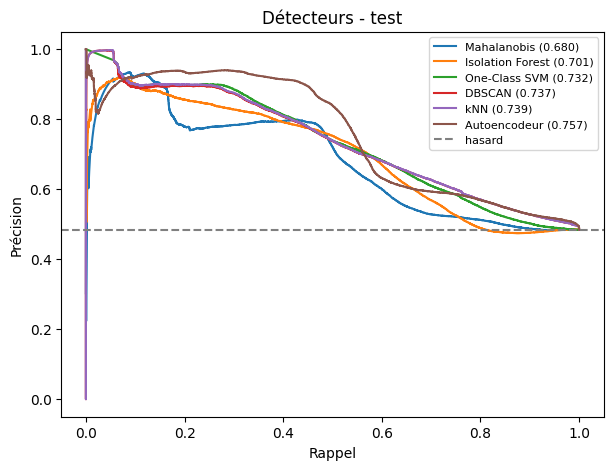

In [6]:
noms = ["Mahalanobis", "Isolation Forest", "One-Class SVM", "DBSCAN", "kNN", "Autoencodeur"]
S_te, T = {}, {}
for nom in noms:
    t = time.time(); f = build(nom, Xtr); tf = time.time() - t
    t = time.time(); S_te[nom] = f(Xte); ts = time.time() - t
    T[nom] = (tf, ts / len(Xte) * 1000)
    print(f"{nom:18s} ajusté en {tf:5.1f} s | score test en {ts:5.1f} s")
np.savez_compressed(BASE + "scores_test.npz", **S_te)

lignes, preds5 = [], {}
for nom in noms:
    for fpr in (0.01, 0.05, 0.10):
        seuil = np.quantile(SV[nom][normal_va], 1 - fpr)
        pred = (S_te[nom] > seuil).astype(int)
        if fpr == 0.05: preds5[nom] = pred
        lignes.append(dict(detecteur=nom, PR_AUC=round(average_precision_score(yte, S_te[nom]), 3),
                           ROC_AUC=round(roc_auc_score(yte, S_te[nom]), 3), FP_cible=fpr,
                           FP_observe=round(pred[normal_te].mean(), 3),
                           precision=round(precision_score(yte, pred, zero_division=0), 3),
                           rappel=round(recall_score(yte, pred), 3), F1=round(f1_score(yte, pred), 3),
                           t_fit_s=round(T[nom][0], 1), ms_par_flux=round(T[nom][1], 3)))
print(f"\n=== TEST - PR-AUC du hasard : {yte.mean():.3f} ===")
res_main = pd.DataFrame(lignes); res_main.to_csv(BASE + "resultats_test.csv", index=False)
print(res_main.to_string(index=False))

plt.figure(figsize=(7, 5))
for nom in noms:
    p, r, _ = precision_recall_curve(yte, S_te[nom]); plt.plot(r, p, label=f"{nom} ({average_precision_score(yte, S_te[nom]):.3f})")
plt.axhline(yte.mean(), ls="--", c="gray", label="hasard")
plt.xlabel("Rappel"); plt.ylabel("Précision"); plt.title("Détecteurs - test"); plt.legend(fontsize=8); plt.show()

In [7]:
# Rappel par famille d'attaque (seuil à 5 % de FP cible)
fam = pd.DataFrame({nom: preds5[nom] for nom in noms}); fam["famille"] = fam_te
att = fam[fam.famille != "Normal"]
tab = att.groupby("famille")[noms].mean().round(3); tab.insert(0, "nb_flux", att.groupby("famille").size())
print("=== Rappel par famille d'attaque (test, FP cible 5 %) ===\n" + tab.to_string())

# Charge d'alertes réaliste : on suppose que rappel et taux de FP mesurés restent valables quand la part d'attaques change
cl = []
for nom in noms:
    fpr_o, rap = preds5[nom][normal_te].mean(), preds5[nom][~normal_te].mean()
    for pi in (0.001, 0.01, 0.10):
        tp, fp = pi * rap, (1 - pi) * fpr_o
        cl.append(dict(detecteur=nom, part_attaques=f"{pi:.1%}", alertes_pour_10000=int(round((tp + fp) * 10000)),
                       part_vraies_attaques=round(tp / (tp + fp), 3)))
print("\n=== Charge d'alertes pour 10 000 flux selon la part réelle d'attaques ===")
print(pd.DataFrame(cl).to_string(index=False))

best = max(noms, key=lambda n: average_precision_score(yte, S_te[n]))
print(f"\nMatrice de confusion - {best} (FP cible 5 %) : lignes = réel normal/attaque, colonnes = prédit normal/alerte")
print(confusion_matrix(yte, preds5[best]))

=== Rappel par famille d'attaque (test, FP cible 5 %) ===
                nb_flux  Mahalanobis  Isolation Forest  One-Class SVM  DBSCAN    kNN  Autoencodeur
famille                                                                                           
Analysis            498        0.311             0.257          0.363   0.321  0.321         0.281
Backdoor            355        0.321             0.304          0.521   0.504  0.504         0.530
DoS                2989        0.359             0.429          0.691   0.645  0.645         0.631
Exploits          18699        0.271             0.518          0.771   0.737  0.737         0.744
Fuzzers           14759        0.085             0.091          0.134   0.142  0.143         0.127
Generic            3686        0.841             0.916          0.953   0.949  0.949         0.942
Reconnaissance     6195        0.071             0.097          0.257   0.220  0.221         0.305
Shellcode          1072        0.001             0.

### 5.3 Métriques opérationnelles (point de vue d'un SOC)

Un analyste regarde moins la PR-AUC que : *combien de vraies attaques trouve-t-on à très faible taux de fausses alertes ? sur les premières alertes, combien sont de vraies attaques ? combien d'alertes faut-il traiter pour trouver la moitié des attaques ?*

- **Rappel à 0,5 %, 1 % et 5 % de faux positifs** : au seuil fixé sur la validation (cas réel, avec le taux de faux positifs observé sur le test) et, en diagnostic, en lisant la courbe ROC du test au taux exact (calibration parfaite).
- **Precision@k** (k = 100, 500, 1000) : part de vraies attaques parmi les *k* flux les plus suspects. Le test contenant 48 % d'attaques, cette mesure y serait presque triviale. On la calcule donc aussi sur des **échantillons réalistes de 10 000 flux contenant 1 % d'attaques** (20 tirages aléatoires de la même population de test ; moyenne ± écart-type).
- **Courbe « alertes à investiguer contre attaques détectées »** : pour une prévalence π = 1 %, le nombre d'alertes pour 10 000 flux vaut 10 000 × (π × rappel + (1 − π) × FP). Cela suppose que rappel et taux de faux positifs mesurés sur le test restent valables pour une autre proportion d'attaques.

=== Rappel à faible taux de faux positifs (test) ===
       detecteur  FP_cible  FP_observe  rappel_au_seuil  rappel_si_FP_exact
     Mahalanobis     0.005      0.0056            0.078               0.055
     Mahalanobis     0.010      0.0095            0.124               0.127
     Mahalanobis     0.050      0.0643            0.232               0.193
Isolation Forest     0.005      0.0073            0.082               0.056
Isolation Forest     0.010      0.0150            0.121               0.097
Isolation Forest     0.050      0.0717            0.343               0.271
   One-Class SVM     0.005      0.0241            0.226               0.071
   One-Class SVM     0.010      0.0529            0.337               0.095
   One-Class SVM     0.050      0.1646            0.499               0.331
          DBSCAN     0.005      0.0249            0.226               0.067
          DBSCAN     0.010      0.0545            0.330               0.090
          DBSCAN     0.050      0.1

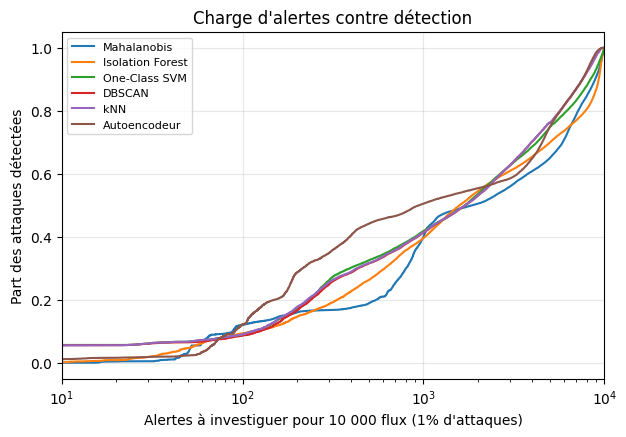


=== Alertes à traiter pour 100 attaques présentes sur 10000 flux ===
       detecteur  alertes_pour_25pct_des_attaques  alertes_pour_50pct_des_attaques
     Mahalanobis                              692                             1848
Isolation Forest                              456                             1579
   One-Class SVM                              285                             1692
          DBSCAN                              301                             1702
             kNN                              291                             1694
    Autoencodeur                              183                              941


In [8]:
from sklearn.metrics import roc_curve
PREV, N_TIRAGES, K_LIST = 0.01, 20, (100, 500, 1000)
i_nor, i_att = np.where(normal_te)[0], np.where(~normal_te)[0]
N_FLUX = int(min(10_000, len(i_nor) / (1 - PREV)))      # 10 000 sur les vraies données

# (a) Rappel à très faible taux de faux positifs
rows, roc_c = [], {}
for nom in noms:
    fpr, tpr, _ = roc_curve(yte, S_te[nom]); roc_c[nom] = (fpr, tpr)
    for cible in (0.005, 0.01, 0.05):
        seuil = np.quantile(SV[nom][normal_va], 1 - cible); pred = S_te[nom] > seuil
        rows.append(dict(detecteur=nom, FP_cible=cible, FP_observe=round(pred[normal_te].mean(), 4),
                         rappel_au_seuil=round(pred[~normal_te].mean(), 3),
                         rappel_si_FP_exact=round(float(np.interp(cible, fpr, tpr)), 3)))
print("=== Rappel à faible taux de faux positifs (test) ===\n" + pd.DataFrame(rows).to_string(index=False))

# (b) Precision@k : population naturelle (48 % d'attaques) et échantillons réalistes (1 %)
rng_b = np.random.default_rng(SEED)
n_att = int(N_FLUX * PREV)
pk = {nom: {k: [] for k in K_LIST} for nom in noms}
for _ in range(N_TIRAGES):
    it = np.concatenate([rng_b.choice(i_nor, N_FLUX - n_att, replace=False), rng_b.choice(i_att, n_att, replace=False)])
    for nom in noms:
        yy = yte[it][np.argsort(-S_te[nom][it], kind="stable")]
        for k in K_LIST: pk[nom][k].append(yy[:k].mean())
rows = []
for nom in noms:
    r = dict(detecteur=nom)
    for k in K_LIST:
        r[f"P@{k} naturel"] = round(yte[np.argsort(-S_te[nom], kind="stable")][:k].mean(), 3)
        r[f"P@{k} (1 % attaques)"] = f"{np.mean(pk[nom][k]):.3f} ± {np.std(pk[nom][k]):.3f}"
    rows.append(r)
print(f"\n=== Precision@k (naturel : {yte.mean():.0%} d'attaques ; réaliste : {PREV:.0%} sur {N_FLUX} flux, {N_TIRAGES} tirages) ===")
print(pd.DataFrame(rows).to_string(index=False))

# (c) Alertes à investiguer vs attaques détectées (prévalence réaliste)
plt.figure(figsize=(7, 4.5)); rows = []
for nom in noms:
    fpr, tpr = roc_c[nom]; x = N_FLUX * (PREV * tpr + (1 - PREV) * fpr)
    plt.plot(x, tpr, label=nom)
    rows.append(dict(detecteur=nom, alertes_pour_25pct_des_attaques=int(round(np.interp(0.25, tpr, x))),
                     alertes_pour_50pct_des_attaques=int(round(np.interp(0.50, tpr, x)))))
plt.xscale("log"); plt.xlim(10, N_FLUX); plt.xlabel(f"Alertes à investiguer pour {N_FLUX:,} flux ({PREV:.0%} d'attaques)".replace(",", " "))
plt.ylabel("Part des attaques détectées"); plt.title("Charge d'alertes contre détection"); plt.grid(alpha=0.3); plt.legend(fontsize=8); plt.show()
print(f"\n=== Alertes à traiter pour {int(n_att)} attaques présentes sur {N_FLUX} flux ===\n" + pd.DataFrame(rows).to_string(index=False))

### 5.4 Intervalles de confiance et comparaison appariée (bootstrap)

Les écarts entre détecteurs (par exemple autoencodeur 0,757 contre kNN 0,739) ne se lisent pas sans mesure d'incertitude. On rééchantillonne **500 fois** les flux du test (tirage avec remise) en utilisant **les mêmes tirages pour tous les détecteurs** (comparaison appariée) ; on obtient un intervalle à 95 % pour la PR-AUC, le rappel et le taux de faux positifs, et un intervalle pour la **différence** entre deux détecteurs.

**Ce que l'intervalle mesure, et ce qu'il ne mesure pas**
- Il mesure l'incertitude due à l'échantillon de test, avec des seuils **déjà fixés** (non réestimés à chaque tirage).
- Il suppose des flux indépendants. Ce n'est pas vérifié : des flux d'une même attaque sont probablement corrélés, donc les intervalles sont sans doute **un peu trop étroits**.
- Il ne mesure ni la dérive entre fichiers, ni la variabilité due aux graines d'entraînement.
- Une différence dont l'intervalle contient 0 n'est **pas démontrée** : on ne conclut pas à une supériorité.

Vérification : écart maximal avec scikit-learn = 1.1e-16
=== Test : estimations et intervalles de confiance à 95 % (500 tirages ; seuils à FP cible 5 %) ===
       detecteur  PR_AUC     IC95_PR_AUC  rappel     IC95_rappel    FP         IC95_FP
     Mahalanobis   0.680 [0.675 ; 0.684]   0.232 [0.228 ; 0.236] 0.064 [0.062 ; 0.066]
Isolation Forest   0.701 [0.696 ; 0.705]   0.343 [0.339 ; 0.346] 0.072 [0.070 ; 0.074]
   One-Class SVM   0.732 [0.728 ; 0.736]   0.499 [0.494 ; 0.503] 0.165 [0.161 ; 0.168]
          DBSCAN   0.737 [0.733 ; 0.741]   0.479 [0.475 ; 0.483] 0.148 [0.145 ; 0.151]
             kNN   0.739 [0.735 ; 0.743]   0.480 [0.475 ; 0.484] 0.147 [0.145 ; 0.150]
    Autoencodeur   0.757 [0.753 ; 0.760]   0.485 [0.481 ; 0.490] 0.080 [0.077 ; 0.082]

=== Différence de PR-AUC : Autoencodeur moins l'autre détecteur ===
          contre  difference                IC95  part_des_tirages_ou_AE_gagne     verdict
     Mahalanobis      0.0769 [+0.0746 ; +0.0789]                          

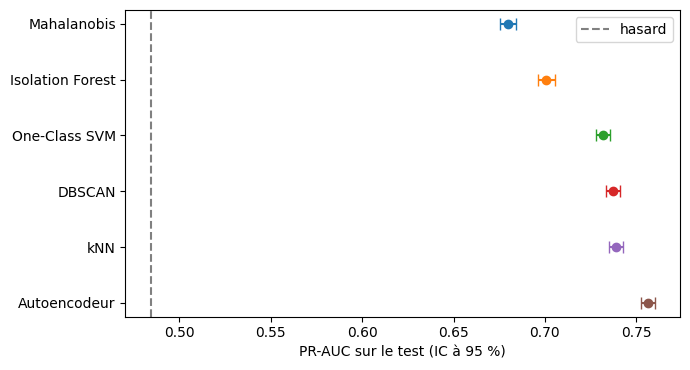

In [9]:
B = 500
rng_bs = np.random.default_rng(SEED)
n_te = len(yte); yb = yte.astype(float)

def trier(s):
    order = np.argsort(-s, kind="stable"); ss = s[order]
    ends = np.r_[np.where(np.diff(ss) != 0)[0], len(ss) - 1]          # fin de chaque groupe de scores égaux
    return order, ends
def ap_pondere(order, ends, w):
    "Average precision avec des poids de rééchantillonnage (même définition que scikit-learn)."
    ws, ys = w[order], yb[order]
    tp = np.cumsum(ws * ys)[ends]; fp = np.cumsum(ws * (1 - ys))[ends]
    prec = tp / np.maximum(tp + fp, 1e-12); rec = tp / tp[-1]
    return float(np.sum(np.diff(np.r_[0.0, rec]) * prec))

tri = {n: trier(S_te[n]) for n in noms}
ecart = max(abs(ap_pondere(*tri[n], np.ones(n_te)) - average_precision_score(yte, S_te[n])) for n in noms)
print(f"Vérification : écart maximal avec scikit-learn = {ecart:.1e}")

flag5 = {n: preds5[n].astype(float) for n in noms}                    # décisions au seuil fixé (FP cible 5 %)
bs_ap, bs_rec, bs_fp = ({n: np.empty(B) for n in noms} for _ in range(3))
for b in range(B):
    w = np.bincount(rng_bs.integers(0, n_te, n_te), minlength=n_te).astype(float)   # mêmes tirages pour tous
    n_att, n_nor = (w * yb).sum(), (w * (1 - yb)).sum()
    for n in noms:
        bs_ap[n][b] = ap_pondere(*tri[n], w)
        bs_rec[n][b] = (w * yb * flag5[n]).sum() / n_att
        bs_fp[n][b] = (w * (1 - yb) * flag5[n]).sum() / n_nor

def ic(x): return np.percentile(x, [2.5, 97.5])
rows = []
for n in noms:
    a, r, f = ic(bs_ap[n]), ic(bs_rec[n]), ic(bs_fp[n])
    rows.append(dict(detecteur=n, PR_AUC=round(average_precision_score(yte, S_te[n]), 3), IC95_PR_AUC=f"[{a[0]:.3f} ; {a[1]:.3f}]",
                     rappel=round(float(preds5[n][~normal_te].mean()), 3), IC95_rappel=f"[{r[0]:.3f} ; {r[1]:.3f}]",
                     FP=round(float(preds5[n][normal_te].mean()), 3), IC95_FP=f"[{f[0]:.3f} ; {f[1]:.3f}]"))
print(f"=== Test : estimations et intervalles de confiance à 95 % ({B} tirages ; seuils à FP cible 5 %) ===")
print(pd.DataFrame(rows).to_string(index=False))

# Comparaison appariée de la PR-AUC : autoencodeur contre chaque autre détecteur
print("\n=== Différence de PR-AUC : Autoencodeur moins l'autre détecteur ===")
rows = []
for n in noms:
    if n == "Autoencodeur": continue
    d = bs_ap["Autoencodeur"] - bs_ap[n]; lo, hi = ic(d)
    rows.append(dict(contre=n, difference=round(float(d.mean()), 4), IC95=f"[{lo:+.4f} ; {hi:+.4f}]",
                     part_des_tirages_ou_AE_gagne=round(float((d > 0).mean()), 3),
                     verdict="AE meilleur" if lo > 0 else ("AE moins bon" if hi < 0 else "non démontré")))
print(pd.DataFrame(rows).to_string(index=False))

# Matrice complète : + (ligne meilleure que colonne), - (moins bonne), = (non démontré)
mat = pd.DataFrame("", index=noms, columns=noms)
for a_ in noms:
    for b_ in noms:
        if a_ == b_: mat.loc[a_, b_] = "."; continue
        lo, hi = ic(bs_ap[a_] - bs_ap[b_]); mat.loc[a_, b_] = "+" if lo > 0 else ("-" if hi < 0 else "=")
print("\n=== Matrice des comparaisons de PR-AUC (ligne contre colonne ; + meilleure, - moins bonne, = non démontré) ===\n" + mat.to_string())

plt.figure(figsize=(7, 3.8))
for i, n in enumerate(noms):
    lo, hi = ic(bs_ap[n]); pt = average_precision_score(yte, S_te[n])
    plt.errorbar(pt, i, xerr=[[pt - lo], [hi - pt]], fmt="o", capsize=4)
plt.yticks(range(len(noms)), noms); plt.axvline(yte.mean(), ls="--", c="gray", label="hasard"); plt.gca().invert_yaxis()
plt.xlabel("PR-AUC sur le test (IC à 95 %)"); plt.legend(); plt.tight_layout(); plt.show()

### 5.5 Calibrer le seuil avec un petit échantillon normal du fichier testing

**Problème mesuré** : un seuil fixé sur le normal de *validation* (même fichier que l'entraînement) ne se transfère pas au *test* : pour 5 % visés, le kNN observe 14,7 %.

**Idée** : fixer le seuil sur un **petit échantillon de trafic normal prélevé dans le fichier testing**, comme on le ferait en déploiement avec une courte période de trafic de référence sain.

**Règles pour que la comparaison reste honnête**
- Les flux de calibration sont **retirés de l'évaluation** (aucune fuite) ; les attaques ne servent jamais à fixer le seuil.
- Les détecteurs ne sont **pas réentraînés** : seul le seuil change. La PR-AUC ne change donc pas.
- On répète avec 30 tirages de l'échantillon (moyenne ± écart-type) et trois tailles (200, 500, 2 000 flux).
- **Hypothèse à signaler** : on dispose d'un échantillon *fiable* de trafic normal du réseau cible. Il utilise l'étiquette « normal » de ces flux, mais aucune étiquette d'attaque.

=== Seuil fixé sur la validation ou calibré sur un échantillon normal du fichier testing ===
       detecteur  FP_cible  FP_seuil_validation  rappel_seuil_validation     FP_cal200  rappel_cal200     FP_cal500  rappel_cal500    FP_cal2000  rappel_cal2000
     Mahalanobis      0.01                0.009                    0.124 0.014 ± 0.007          0.125 0.012 ± 0.004          0.122 0.011 ± 0.003           0.127
     Mahalanobis      0.05                0.064                    0.232 0.057 ± 0.018          0.227 0.051 ± 0.010          0.200 0.051 ± 0.005           0.196
Isolation Forest      0.01                0.015                    0.121 0.016 ± 0.010          0.120 0.010 ± 0.004          0.093 0.010 ± 0.002           0.098
Isolation Forest      0.05                0.072                    0.343 0.059 ± 0.019          0.297 0.051 ± 0.010          0.274 0.051 ± 0.006           0.274
   One-Class SVM      0.01                0.053                    0.337 0.017 ± 0.009          0.161 

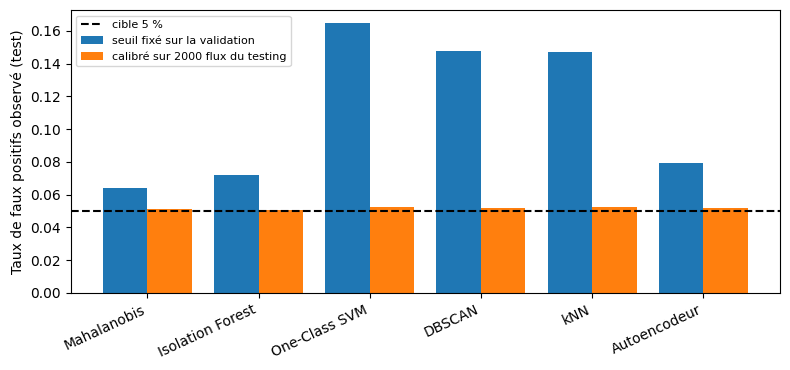

In [10]:
CIBLES, N_CAL, N_TIR = (0.01, 0.05), (200, 500, 2000), 30
i_nor_te = np.where(normal_te)[0]
N_CAL = tuple(n for n in N_CAL if n <= len(i_nor_te) // 2)
rng_c = np.random.default_rng(SEED)
tirages = {n: [rng_c.choice(i_nor_te, n, replace=False) for _ in range(N_TIR)] for n in N_CAL}   # mêmes tirages pour tous les détecteurs

rows, num = [], []
for nom in noms:
    s = S_te[nom]
    for cible in CIBLES:
        thr_v = np.quantile(SV[nom][normal_va], 1 - cible)
        fp_v, rec_v = float((s[normal_te] > thr_v).mean()), float((s[~normal_te] > thr_v).mean())
        r = dict(detecteur=nom, FP_cible=cible, FP_seuil_validation=round(fp_v, 3), rappel_seuil_validation=round(rec_v, 3))
        moy = {}
        for n in N_CAL:
            fps, recs = [], []
            for idx in tirages[n]:
                thr_c = np.quantile(s[idx], 1 - cible)                  # seuil calibré sur l'échantillon normal du fichier testing
                ev = normal_te.copy(); ev[idx] = False                    # ces flux sortent de l'évaluation
                fps.append(float((s[ev] > thr_c).mean())); recs.append(float((s[~normal_te] > thr_c).mean()))
            r[f"FP_cal{n}"] = f"{np.mean(fps):.3f} ± {np.std(fps):.3f}"; r[f"rappel_cal{n}"] = round(float(np.mean(recs)), 3)
            moy[n] = float(np.mean(fps))
        rows.append(r); num.append((nom, cible, fp_v, moy))
print("=== Seuil fixé sur la validation ou calibré sur un échantillon normal du fichier testing ===")
print(pd.DataFrame(rows).to_string(index=False))

print("\n=== Écart moyen entre le FP observé et le FP visé (moyenne sur les détecteurs) ===")
for cible in CIBLES:
    sub = [t for t in num if t[1] == cible]
    ligne = f"cible {cible:.0%} : seuil validation = {np.mean([abs(t[2] - cible) for t in sub]):.3f}"
    for n in N_CAL: ligne += f" | calibré sur {n} flux = {np.mean([abs(t[3][n] - cible) for t in sub]):.3f}"
    print(ligne)

n_plot = max(N_CAL); sub = [t for t in num if t[1] == 0.05]
x = np.arange(len(sub)); plt.figure(figsize=(8, 3.8))
plt.bar(x - 0.2, [t[2] for t in sub], 0.4, label="seuil fixé sur la validation"); plt.bar(x + 0.2, [t[3][n_plot] for t in sub], 0.4, label=f"calibré sur {n_plot} flux du testing")
plt.axhline(0.05, c="k", ls="--", label="cible 5 %"); plt.xticks(x, [t[0] for t in sub], rotation=25, ha="right")
plt.ylabel("Taux de faux positifs observé (test)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Robustesse : contamination de l'entraînement

On remplace 1 % puis 5 % des flux normaux d'entraînement par des attaques (tirées au hasard dans les attaques de la **validation**, jamais du test), en gardant la **même taille d'entraînement**. Hyperparamètres gelés ; le seuil est recalculé sur le normal de validation avec le modèle contaminé. 3 graines par taux. L'évaluation porte sur un sous-échantillon aléatoire fixe du test (30 000 flux) pour limiter le temps de calcul ; la valeur à 0 % est recalculée sur ce même sous-échantillon. DBSCAN n'est pas répété car il est équivalent au kNN ici (voir section 5).

`INCLURE_OCSVM = False` accélère beaucoup la cellule (le One-Class SVM prend environ 100 s par ajustement).

Test échantillonné : 30000 flux, 48.3% d'attaques (hasard = 0.483)
Mahalanobis       contamination 0% terminée
Mahalanobis       contamination 1% terminée
Mahalanobis       contamination 5% terminée
Isolation Forest  contamination 0% terminée
Isolation Forest  contamination 1% terminée
Isolation Forest  contamination 5% terminée
kNN               contamination 0% terminée
kNN               contamination 1% terminée
kNN               contamination 5% terminée
Autoencodeur      contamination 0% terminée
Autoencodeur      contamination 1% terminée
Autoencodeur      contamination 5% terminée
One-Class SVM     contamination 0% terminée
One-Class SVM     contamination 1% terminée
One-Class SVM     contamination 5% terminée

=== Effet de la contamination (moyenne et écart-type sur 3 graines ; à 0 % : un seul calcul) ===
                      PR_AUC        rappel        FP_observe       
                        mean    std   mean    std       mean    std
detecteur        taux                  

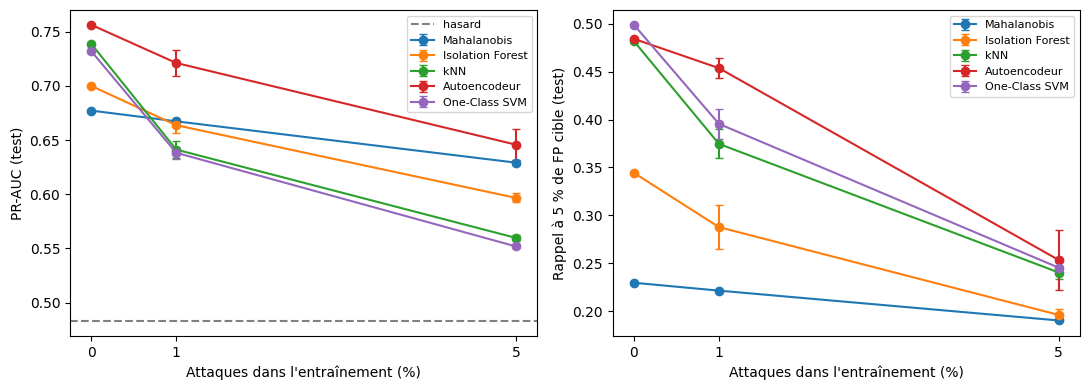


=== Rappel par famille : 0 % vs 5 % de contamination ===
taux                               0.0   0.01   0.05  variation_5pct
detecteur        famille                                            
Autoencodeur     Analysis        0.327  0.375  0.257          -0.070
                 Backdoor        0.495  0.461  0.283          -0.212
                 DoS             0.641  0.608  0.420          -0.221
                 Exploits        0.737  0.704  0.449          -0.288
                 Fuzzers         0.128  0.137  0.102          -0.026
                 Generic         0.943  0.698  0.108          -0.834
                 Reconnaissance  0.316  0.308  0.069          -0.247
                 Shellcode       0.010  0.038  0.014           0.004
                 Worms           0.656  0.760  0.281          -0.375
Isolation Forest Analysis        0.281  0.257  0.192          -0.089
                 Backdoor        0.303  0.273  0.212          -0.091
                 DoS             0.454  0.377

In [11]:
INCLURE_OCSVM = True
TAUX, GRAINES = [0.0, 0.01, 0.05], [0, 1, 2]
N_TEST = min(30000, len(Xte))

idx = np.random.default_rng(SEED).choice(len(Xte), N_TEST, replace=False)
Xs, ys, fs = Xte[idx], yte[idx], fam_te[idx]
Xva_n, Xva_att = Xva[yva == 0], Xva[yva == 1]
print(f"Test échantillonné : {N_TEST} flux, {ys.mean():.1%} d'attaques (hasard = {ys.mean():.3f})")

def train_contamine(taux, graine):
    if taux == 0: return Xtr
    r = np.random.default_rng(1000 + graine)
    n_att = int(round(taux * len(Xtr)))
    i_att = r.choice(len(Xva_att), n_att, replace=False)
    i_nor = r.choice(len(Xtr), len(Xtr) - n_att, replace=False)
    return np.vstack([Xtr[i_nor], Xva_att[i_att]])

noms_c = ["Mahalanobis", "Isolation Forest", "kNN", "Autoencodeur"] + (["One-Class SVM"] if INCLURE_OCSVM else [])
rows, fam_rows = [], []
for nom in noms_c:
    for taux in TAUX:
        for g in ([0] if taux == 0 else GRAINES):
            f = build(nom, train_contamine(taux, g))
            seuil = np.quantile(f(Xva_n), 0.95)
            s = f(Xs); pred = s > seuil
            rows.append(dict(detecteur=nom, taux=taux, graine=g, PR_AUC=average_precision_score(ys, s),
                             rappel=pred[ys == 1].mean(), FP_observe=pred[ys == 0].mean()))
            for fa in np.unique(fs[ys == 1]):
                fam_rows.append(dict(detecteur=nom, taux=taux, graine=g, famille=fa, rappel=pred[fs == fa].mean()))
        print(f"{nom:17s} contamination {taux:.0%} terminée")

R = pd.DataFrame(rows)
res = R.groupby(["detecteur", "taux"])[["PR_AUC", "rappel", "FP_observe"]].agg(["mean", "std"]).round(3).fillna(0)
print("\n=== Effet de la contamination (moyenne et écart-type sur 3 graines ; à 0 % : un seul calcul) ===\n" + res.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nom in noms_c:
    g = R[R.detecteur == nom].groupby("taux")
    mm, sd = g[["PR_AUC", "rappel"]].mean(), g[["PR_AUC", "rappel"]].std().fillna(0)
    for a, col in zip(ax, ["PR_AUC", "rappel"]):
        a.errorbar(mm.index * 100, mm[col], yerr=sd[col], marker="o", capsize=3, label=nom)
ax[0].axhline(ys.mean(), ls="--", c="gray", label="hasard")
ax[0].set_ylabel("PR-AUC (test)"); ax[1].set_ylabel("Rappel à 5 % de FP cible (test)")
for a in ax: a.set_xlabel("Attaques dans l'entraînement (%)"); a.set_xticks([0, 1, 5]); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

F = pd.DataFrame(fam_rows).groupby(["detecteur", "taux", "famille"])["rappel"].mean().unstack("taux")
F["variation_5pct"] = (F[0.05] - F[0.0]).round(3)
print("\n=== Rappel par famille : 0 % vs 5 % de contamination ===\n" + F.round(3).to_string())
R.to_csv(BASE + "contamination_resultats.csv", index=False)

### 6.2 Entraînement robuste à la contamination (élagage des flux les plus suspects)

**Problème mesuré** (section 6) : avec 5 % d'attaques dans l'entraînement, le rappel est divisé par deux pour la plupart des détecteurs.

**Méthode testée** : on ajuste le détecteur sur l'entraînement contaminé, on **retire les 10 % de flux d'entraînement les plus suspects** selon ce détecteur, puis on **réajuste** sur le reste. La part élaguée (10 %) est **fixée à l'avance** (supérieure à la contamination maximale de 5 %) et n'est pas réglée sur le test.

**Précautions**
- Mêmes jeux contaminés, mêmes graines et même sous-échantillon de test que la section 6 : les résultats se comparent directement (à lire après la section 6, dont cette cellule réutilise `R` et `fam_rows`).
- À 0 % de contamination, l'élagage retire 10 % de flux *normaux* : cela mesure son coût.
- Pour le kNN, le score d'un flux d'entraînement est la distance à son plus proche *autre* flux. Attendu : des attaques très semblables entre elles (famille Generic) ont chacune un voisin proche et échappent à l'élagage.
- On mesure la **part des attaques injectées réellement retirées**, pour savoir si l'élagage fonctionne ou non.

Mahalanobis terminé
Isolation Forest terminé
kNN terminé
Autoencodeur terminé

=== Élagage de 10% des flux d'entraînement les plus suspects (test, FP cible 5 %) ===
                       PR_AUC_sans_elagage  PR_AUC_elagage  ecart_type  rappel_sans_elagage  rappel_elagage  FP_elagage  attaques_injectees_retirees  gain_PR_AUC
detecteur        taux                                                                                                                                            
Autoencodeur     0.00                0.756           0.739       0.000                0.484           0.432       0.055                          NaN       -0.017
                 0.01                0.721           0.743       0.018                0.454           0.449       0.049                        0.626        0.022
                 0.05                0.646           0.664       0.021                0.253           0.284       0.057                        0.420        0.018
Isolation Forest 0.00    

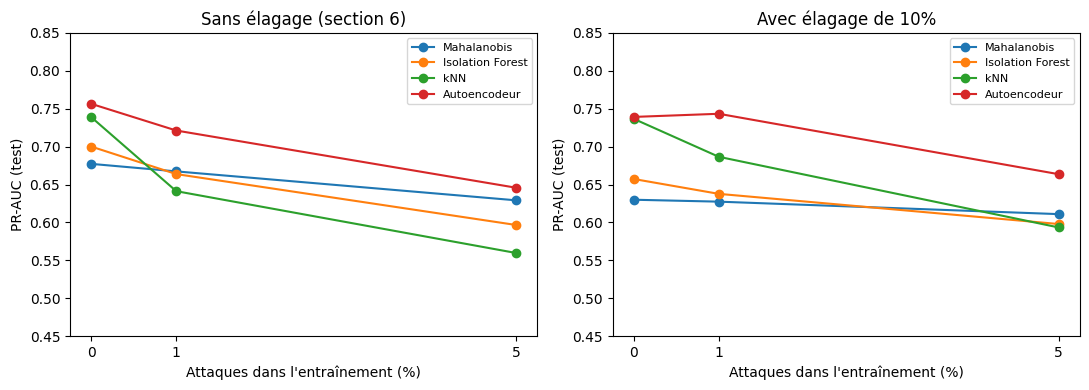

In [12]:
assert "R" in globals() and "fam_rows" in globals(), "Exécuter d'abord la section 6 (contamination)."
INCLURE_OCSVM_R = False                 # True : ajoute le One-Class SVM (très long)
TRIM, TAUX_R, GRAINES_R = 0.10, [0.0, 0.01, 0.05], [0, 1, 2]
noms_r = ["Mahalanobis", "Isolation Forest", "kNN", "Autoencodeur"] + (["One-Class SVM"] if INCLURE_OCSVM_R else [])

N_TEST_R = min(30000, len(Xte))
idx_r = np.random.default_rng(SEED).choice(len(Xte), N_TEST_R, replace=False)       # même sous-échantillon que la section 6
Xs_r, ys_r, fs_r = Xte[idx_r], yte[idx_r], fam_te[idx_r]
Xva_n_r, Xva_att_r = Xva[yva == 0], Xva[yva == 1]
def contamine_r(taux, graine):
    if taux == 0: return Xtr, 0
    r = np.random.default_rng(1000 + graine); n_att = int(round(taux * len(Xtr)))
    i_att = r.choice(len(Xva_att_r), n_att, replace=False); i_nor = r.choice(len(Xtr), len(Xtr) - n_att, replace=False)
    return np.vstack([Xtr[i_nor], Xva_att_r[i_att]]), n_att                         # les n_att dernières lignes sont des attaques
def score_train(nom, f, Xc):
    if nom == "kNN": return NearestNeighbors(n_neighbors=2).fit(Xc).kneighbors(Xc)[0][:, 1]     # distance au plus proche AUTRE flux
    return f(Xc)

rows_r, fam_rob = [], []
for nom in noms_r:
    for taux in TAUX_R:
        for g in ([0] if taux == 0 else GRAINES_R):
            Xc, n_att = contamine_r(taux, g)
            s0 = score_train(nom, build(nom, Xc), Xc)
            garde = s0 <= np.quantile(s0, 1 - TRIM)                                   # on retire les TRIM % les plus suspects
            f1 = build(nom, Xc[garde])
            seuil = np.quantile(f1(Xva_n_r), 0.95); s = f1(Xs_r); pred = s > seuil
            rows_r.append(dict(detecteur=nom, taux=taux, graine=g, PR_AUC=average_precision_score(ys_r, s), rappel=pred[ys_r == 1].mean(),
                               FP_observe=pred[ys_r == 0].mean(),
                               attaques_retirees=(1 - garde[len(Xc) - n_att:].mean()) if n_att else np.nan))
            for fa in np.unique(fs_r[ys_r == 1]):
                fam_rob.append(dict(detecteur=nom, taux=taux, graine=g, famille=fa, rappel=pred[fs_r == fa].mean()))
    print(f"{nom} terminé")

Rr = pd.DataFrame(rows_r)
base = R[R.detecteur.isin(noms_r)].groupby(["detecteur", "taux"])[["PR_AUC", "rappel"]].mean()
rob = Rr.groupby(["detecteur", "taux"]).agg(PR_AUC=("PR_AUC", "mean"), PR_AUC_ecart=("PR_AUC", "std"), rappel=("rappel", "mean"),
                                           FP_observe=("FP_observe", "mean"), attaques_retirees=("attaques_retirees", "mean"))
cmp_ = pd.DataFrame({"PR_AUC_sans_elagage": base["PR_AUC"], "PR_AUC_elagage": rob["PR_AUC"], "ecart_type": rob["PR_AUC_ecart"].fillna(0),
                     "rappel_sans_elagage": base["rappel"], "rappel_elagage": rob["rappel"], "FP_elagage": rob["FP_observe"],
                     "attaques_injectees_retirees": rob["attaques_retirees"]}).round(3)
cmp_["gain_PR_AUC"] = (cmp_["PR_AUC_elagage"] - cmp_["PR_AUC_sans_elagage"]).round(3)
print(f"\n=== Élagage de {TRIM:.0%} des flux d'entraînement les plus suspects (test, FP cible 5 %) ===\n" + cmp_.to_string())

fb = pd.DataFrame(fam_rows).query("taux == 0.05").groupby(["detecteur", "famille"])["rappel"].mean()
fr = pd.DataFrame(fam_rob).query("taux == 0.05").groupby(["detecteur", "famille"])["rappel"].mean()
fam_cmp = pd.DataFrame({"sans_elagage": fb, "elagage": fr}).dropna().round(3); fam_cmp["gain"] = (fam_cmp["elagage"] - fam_cmp["sans_elagage"]).round(3)
print("\n=== Rappel par famille à 5 % de contamination : sans élagage contre élagage (familles Generic, Exploits, DoS) ===")
print(fam_cmp[fam_cmp.index.get_level_values("famille").isin(["Generic", "Exploits", "DoS"])].to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nom in noms_r:
    ax[0].plot([t * 100 for t in TAUX_R], [base.loc[(nom, t), "PR_AUC"] for t in TAUX_R], "o-", label=nom)
    ax[1].plot([t * 100 for t in TAUX_R], [rob.loc[(nom, t), "PR_AUC"] for t in TAUX_R], "o-", label=nom)
ax[0].set_title("Sans élagage (section 6)"); ax[1].set_title(f"Avec élagage de {TRIM:.0%}")
for a in ax: a.set_xlabel("Attaques dans l'entraînement (%)"); a.set_ylabel("PR-AUC (test)"); a.set_xticks([0, 1, 5]); a.set_ylim(0.45, 0.85); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
Rr.to_csv(BASE + "contamination_elagage_resultats.csv", index=False)

## 7. Borne supérieure supervisée

Pour chiffrer ce que coûte l'absence d'étiquettes, on entraîne une **forêt aléatoire** et **XGBoost** *avec* étiquettes sur tout le fichier training nettoyé (entraînement + validation). Hyperparamètres réglés par validation croisée (3 plis) sur cet ensemble ; le test n'est utilisé qu'une fois. Le seuil à 5 % de faux positifs est calculé sur des prédictions **hors pli** (sans fuite).

> Comparaison non à armes égales : le supervisé voit 53 952 flux étiquetés, les détecteurs non supervisés 23 944 flux normaux sans étiquette.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier

Xall = np.vstack([Xtr, Xva]); yall = np.concatenate([np.zeros(len(Xtr), int), yva])
print("Ensemble étiqueté :", Xall.shape, f"| attaques : {yall.mean():.1%}")
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
modeles = {
    "Forêt aléatoire": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                        {"n_estimators": [300], "max_depth": [None, 20], "min_samples_leaf": [1, 5]}),
    "XGBoost": (XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=-1, eval_metric="logloss"),
                {"n_estimators": [300], "max_depth": [4, 8], "learning_rate": [0.05, 0.1]}),
}
lignes, preds, S_sup = [], {}, {}
for nom, (mdl, grille) in modeles.items():
    t = time.time()
    gs = GridSearchCV(mdl, grille, scoring="average_precision", cv=cv, n_jobs=1).fit(Xall, yall)
    tf = time.time() - t
    print(f"\n{nom} - meilleurs paramètres : {gs.best_params_} (PR-AUC en CV : {gs.best_score_:.3f}) | {tf:.0f} s")
    oof = cross_val_predict(gs.best_estimator_, Xall, yall, cv=cv, method="predict_proba")[:, 1]
    seuil = np.quantile(oof[yall == 0], 0.95)
    t = time.time(); s = gs.best_estimator_.predict_proba(Xte)[:, 1]; ts = time.time() - t
    pred = (s > seuil).astype(int); preds[nom] = pred; S_sup[nom] = s
    lignes.append(dict(modele=nom, PR_AUC=round(average_precision_score(yte, s), 3), ROC_AUC=round(roc_auc_score(yte, s), 3),
                       FP_cible=0.05, FP_observe=round(pred[yte == 0].mean(), 3),
                       precision=round(precision_score(yte, pred), 3), rappel=round(recall_score(yte, pred), 3),
                       F1=round(f1_score(yte, pred), 3), t_fit_s=round(tf, 0), ms_par_flux=round(ts / len(Xte) * 1000, 4)))
print(f"\n=== TEST supervisé - PR-AUC du hasard : {yte.mean():.3f} ===\n" + pd.DataFrame(lignes).to_string(index=False))

fsup = pd.DataFrame(preds); fsup["famille"] = fam_te
print("\n=== Rappel par famille (test, FP cible 5 %), supervisé ===")
print(fsup[fsup.famille != "Normal"].groupby("famille")[list(modeles)].mean().round(3).to_string())
print("\nPR-AUC test des détecteurs non supervisés :", {n: round(average_precision_score(yte, S_te[n]), 3) for n in noms})
PRED_SUP = preds

Ensemble étiqueté : (53952, 58) | attaques : 36.6%

Forêt aléatoire - meilleurs paramètres : {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300} (PR-AUC en CV : 0.989) | 374 s

XGBoost - meilleurs paramètres : {'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 300} (PR-AUC en CV : 0.993) | 66 s

=== TEST supervisé - PR-AUC du hasard : 0.484 ===
         modele  PR_AUC  ROC_AUC  FP_cible  FP_observe  precision  rappel    F1  t_fit_s  ms_par_flux
Forêt aléatoire   0.970    0.972      0.05       0.035      0.953   0.771 0.853    374.0       0.0339
        XGBoost   0.968    0.972      0.05       0.039      0.949   0.777 0.854     66.0       0.0080

=== Rappel par famille (test, FP cible 5 %), supervisé ===
                Forêt aléatoire  XGBoost
famille                                 
Analysis                  0.307    0.281
Backdoor                  0.994    0.989
DoS                       0.969    0.970
Exploits                  0.969    0.975
Fuzzers                   0

## 8. Analyse critique des familles difficiles

Les détecteurs non supervisés ratent presque entièrement certaines familles (Fuzzers, Reconnaissance, Shellcode) et détectent mal Analysis. Deux explications s'opposent :
- **H1 : ces attaques ressemblent trop au trafic légitime** (elles ne sont pas discernables même avec étiquettes) ;
- **H2 : elles sont différentes du normal mais pas « atypiques »** : un détecteur de densité ou de distance ne les isole pas, alors qu'un modèle qui a vu des exemples les sépare.

La section 7 donne un indice : Reconnaissance et Shellcode sont très bien détectées en supervisé, ce qui favorise H2 pour elles. On le **mesure** ici.

**Quatre analyses**
1. **AUC « famille contre normal »** pour chaque détecteur non supervisé et pour XGBoost (supervisé). Verdict descriptif selon des seuils conventionnels (non optimisés) : *détectable sans étiquettes* si le meilleur AUC non supervisé ≥ 0,80 ; *différente du normal mais pas atypique* si AUC supervisé ≥ 0,90 ; *ressemble au normal, même avec étiquettes* si AUC supervisé < 0,80 ; sinon *intermédiaire*.
2. **Rang des flux de la famille** par rapport au trafic normal de validation : part des flux de la famille qui paraissent *plus normaux que le flux normal médian*.
3. **Stabilité entre fichiers** : AUC (kNN) sur la validation (même fichier que l'entraînement) et sur le test (autre fichier).
4. **Statistiques par variable** : pour chaque famille difficile, les variables qui la séparent le mieux du normal (AUC univarié), avec leurs médianes.

=== 1. AUC « famille contre normal » (test ; 0,5 = indiscernable) ===
       famille  nb_flux  Mahalanobis  Isolation Forest  One-Class SVM  DBSCAN   kNN  Autoencodeur  XGBoost (supervisé)                                verdict
      Analysis      498        0.712             0.688          0.577   0.606 0.606         0.725                0.884                          intermédiaire
      Backdoor      355        0.667             0.657          0.790   0.799 0.799         0.790                0.996 différente du normal mais pas atypique
           DoS     2989        0.779             0.808          0.841   0.815 0.816         0.861                0.993             détectable sans étiquettes
      Exploits    18699        0.818             0.843          0.879   0.868 0.869         0.903                0.995             détectable sans étiquettes
       Fuzzers    14759        0.419             0.437          0.454   0.523 0.524         0.509                0.922 différente du normal 

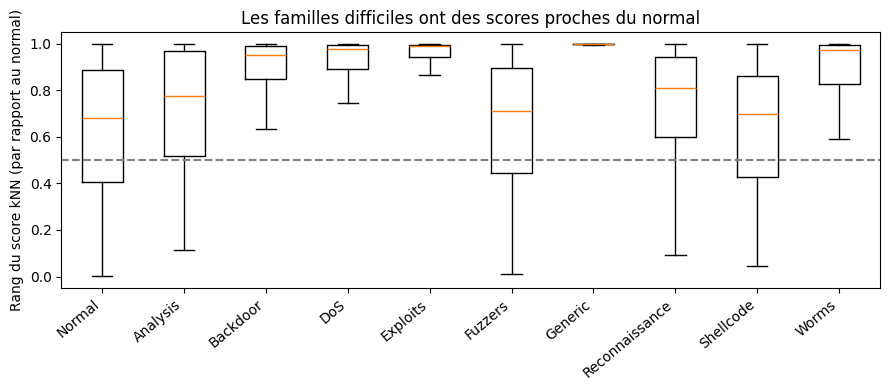


=== 3. Stabilité entre fichiers (kNN, AUC famille contre normal) ===
       famille  AUC_validation  AUC_test  ecart
      Analysis           0.992     0.606 -0.386
      Backdoor           0.906     0.799 -0.107
           DoS           0.903     0.816 -0.087
      Exploits           0.939     0.869 -0.070
       Fuzzers           0.829     0.524 -0.305
       Generic           0.973     0.965 -0.008
Reconnaissance           0.748     0.614 -0.134
     Shellcode           0.651     0.497 -0.154
         Worms           0.848     0.773 -0.075

=== 4. Variables qui séparent le mieux chaque famille difficile du trafic normal (test) ===

[Fuzzers]  (14759 flux)
    variable  separabilite   AUC  mediane_famille  mediane_normal
        sttl         0.810 0.905           254.00           31.00
ct_state_ttl         0.742 0.871             1.00            0.00
       dload         0.738 0.131          3001.03       550840.25
       dmean         0.638 0.181            45.00           89.00
  

In [14]:
famil = [f for f in np.unique(fam_te) if f != "Normal"]
DIFF = [f for f in ["Fuzzers", "Reconnaissance", "Shellcode", "Analysis"] if f in famil]
XG = S_sup["XGBoost"]

def auc_fam(score, fam_arr, f):
    m = (fam_arr == f) | (fam_arr == "Normal")
    return roc_auc_score((fam_arr[m] == f).astype(int), score[m])

# 1. AUC famille contre normal
rows = []
for f in famil:
    r = dict(famille=f, nb_flux=int((fam_te == f).sum()))
    for n in noms: r[n] = round(auc_fam(S_te[n], fam_te, f), 3)
    r["XGBoost (supervisé)"] = round(auc_fam(XG, fam_te, f), 3)
    best_u, sup = max(r[n] for n in noms), r["XGBoost (supervisé)"]
    r["verdict"] = ("détectable sans étiquettes" if best_u >= 0.80 else
                    "différente du normal mais pas atypique" if sup >= 0.90 else
                    "ressemble au normal, même avec étiquettes" if sup < 0.80 else "intermédiaire")
    rows.append(r)
print("=== 1. AUC « famille contre normal » (test ; 0,5 = indiscernable) ===\n" + pd.DataFrame(rows).to_string(index=False))

# 2. rang par rapport au normal de validation
def rang_normal(nom, s):
    r = np.sort(SV[nom][normal_va]); return np.searchsorted(r, s, side="right") / len(r)
REF = ["kNN", "Isolation Forest", "Autoencodeur"]
rows = []
for f in ["Normal"] + famil:
    m = fam_te == f; r = dict(famille=f, nb_flux=int(m.sum()))
    for n in REF:
        rk = rang_normal(n, S_te[n][m]); r[f"{n} : rang médian"] = round(float(np.median(rk)), 2); r[f"{n} : part sous la médiane du normal"] = round(float((rk < 0.5).mean()), 2)
    rows.append(r)
print("\n=== 2. Rang par rapport au normal de validation (0,5 = typique ; proche de 1 = très atypique) ===\n" + pd.DataFrame(rows).to_string(index=False))
plt.figure(figsize=(9, 4)); data = [rang_normal("kNN", S_te["kNN"][fam_te == f]) for f in ["Normal"] + famil]
plt.boxplot(data, showfliers=False); plt.xticks(range(1, len(data) + 1), ["Normal"] + famil, rotation=40, ha="right")
plt.axhline(0.5, c="gray", ls="--"); plt.ylabel("Rang du score kNN (par rapport au normal)"); plt.title("Les familles difficiles ont des scores proches du normal"); plt.tight_layout(); plt.show()

# 3. stabilité validation -> test (kNN)
rows = [dict(famille=f, AUC_validation=round(auc_fam(SV["kNN"], fam_va, f), 3), AUC_test=round(auc_fam(S_te["kNN"], fam_te, f), 3)) for f in famil if (fam_va == f).sum() > 5]
d3 = pd.DataFrame(rows); d3["ecart"] = (d3["AUC_test"] - d3["AUC_validation"]).round(3)
print("\n=== 3. Stabilité entre fichiers (kNN, AUC famille contre normal) ===\n" + d3.to_string(index=False))

# 4. variables qui séparent la famille du normal
num_idx = [j for j in range(Xte.shape[1]) if is_num[j]]
def stats_famille(f, top=5):
    m_f, m_n = fam_te == f, fam_te == "Normal"; out = []
    for j in num_idx:
        x_f, x_n = Xte[m_f, j], Xte[m_n, j]
        if x_f.std() == 0 and x_n.std() == 0: continue
        a = roc_auc_score(np.r_[np.ones(m_f.sum()), np.zeros(m_n.sum())], np.r_[x_f, x_n]); b = noms_var[j]
        out.append((b, abs(2 * a - 1), a, float(np.median(test.loc[m_f, b])), float(np.median(test.loc[m_n, b]))))
    out.sort(key=lambda t: -t[1])
    return pd.DataFrame(out[:top], columns=["variable", "separabilite", "AUC", "mediane_famille", "mediane_normal"]).round(3)
print("\n=== 4. Variables qui séparent le mieux chaque famille difficile du trafic normal (test) ===")
for f in DIFF:
    print(f"\n[{f}]  ({int((fam_te == f).sum())} flux)\n" + stats_famille(f).to_string(index=False))
    for cat in ("proto", "state"):
        pf = test.loc[fam_te == f, cat].value_counts(normalize=True).head(3).round(2).to_dict()
        pn = test.loc[fam_te == "Normal", cat].value_counts(normalize=True).head(3).round(2).to_dict()
        print(f"   {cat} dominants : famille {pf} | normal {pn}")

## 9. Combinaison : détecteur non supervisé puis classifieur supervisé

**Idée (extension du cahier des charges).** Le détecteur non supervisé filtre le trafic ; un petit classifieur supervisé ne regarde que les flux qu'il a signalés, pour écarter ses fausses alertes.

**Protocole**
- **Étage 1** : le détecteur ayant la meilleure PR-AUC **en validation** ; seuil permissif à 10 % de faux positifs sur le normal de validation (fixé à l'avance), pour garder un rappel élevé.
- **Étage 2** : XGBoost entraîné sur les **seuls flux de la validation signalés par l'étage 1** (entrées : variables + score de l'étage 1), réglé par validation croisée (3 plis). Le seuil de l'étage 2 est calibré sur des prédictions **hors pli** pour que le système complet ait **5 % de faux positifs** sur le normal de validation.
- Le test n'est utilisé qu'une fois pour évaluer.

**Limites à garder en tête**
- Le rappel du système ne peut **pas dépasser** celui de l'étage 1 à 10 % de faux positifs.
- L'étage 2 utilise des étiquettes d'attaque (celles de la validation) : le système n'est plus purement non supervisé.
- Il apprend sur des attaques du fichier *training* et est évalué sur le fichier *testing* : la dérive entre fichiers peut limiter le gain.

In [15]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict

CIBLE_FP, FP_ETAGE1 = 0.05, 0.10
best1 = max(noms, key=lambda n: average_precision_score(yva, SV[n]))
seuil1 = np.quantile(SV[best1][normal_va], 1 - FP_ETAGE1)
flag_va, flag_te = SV[best1] > seuil1, S_te[best1] > seuil1
print(f"Étage 1 : {best1} (meilleure PR-AUC en validation : {average_precision_score(yva, SV[best1]):.3f}) | seuil à {FP_ETAGE1:.0%} de FP")
print(f"Flux signalés : validation {flag_va.sum()} ({yva[flag_va].mean():.1%} d'attaques) | test {flag_te.sum()} ({yte[flag_te].mean():.1%} d'attaques)")
print(f"Plafond de rappel de l'étage 1 sur le test : {flag_te[~normal_te].mean():.3f}")

X2_va = np.column_stack([Xva[flag_va], SV[best1][flag_va]]); y2_va = yva[flag_va]
X2_te = np.column_stack([Xte[flag_te], S_te[best1][flag_te]])
cv2 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
gs2 = GridSearchCV(XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=-1, eval_metric="logloss"),
                   {"n_estimators": [200], "max_depth": [3, 6], "learning_rate": [0.05, 0.1]},
                   scoring="average_precision", cv=cv2).fit(X2_va, y2_va)
clf2 = gs2.best_estimator_
print(f"Étage 2 : {gs2.best_params_} (PR-AUC en validation croisée : {gs2.best_score_:.3f})")

# seuil de l'étage 2 : FP global sur le normal de validation = CIBLE_FP, avec des prédictions hors pli
oof = cross_val_predict(clf2, X2_va, y2_va, cv=cv2, method="predict_proba")[:, 1]
nf = (y2_va == 0)
garde = min(CIBLE_FP * normal_va.sum() / nf.sum(), 1.0)
thr2 = float(np.quantile(oof[nf], 1 - garde))
alert_te = np.zeros(len(Xte), bool); alert_te[np.where(flag_te)[0]] = clf2.predict_proba(X2_te)[:, 1] > thr2

def ligne(nom, pred):
    pred = np.asarray(pred).astype(int); fp, rec = pred[normal_te].mean(), pred[~normal_te].mean()
    al = N_FLUX * (PREV * rec + (1 - PREV) * fp)
    return dict(systeme=nom, FP_test=round(fp, 3), precision_test=round(precision_score(yte, pred, zero_division=0), 3),
                rappel=round(rec, 3), F1=round(f1_score(yte, pred, zero_division=0), 3),
                alertes_pour_10000_a_1pct=int(round(al)),
                precision_a_1pct=round(PREV * rec / (PREV * rec + (1 - PREV) * fp), 3) if (rec + fp) > 0 else None)
rows = [ligne(f"{best1} seul (FP cible 5 %)", preds5[best1]),
        ligne(f"{best1} seul (FP cible {FP_ETAGE1:.0%}, étage 1)", flag_te),
        ligne(f"COMBINAISON {best1} + XGBoost (FP cible 5 %)", alert_te),
        ligne("XGBoost supervisé complet (borne supérieure, FP cible 5 %)", PRED_SUP["XGBoost"])]
res_comb = pd.DataFrame(rows); res_comb.to_csv(BASE + "resultats_combinaison.csv", index=False)
print(f"\n=== COMBINAISON vs détecteur seul vs supervisé (test, hasard {yte.mean():.3f}) ===\n" + res_comb.to_string(index=False))
print("\nLes deux dernières colonnes supposent une prévalence réaliste de 1 % d'attaques (rappel et FP supposés inchangés).")

Étage 1 : One-Class SVM (meilleure PR-AUC en validation : 0.943) | seuil à 10% de FP
Flux signalés : validation 15776 (93.5% d'attaques) | test 42203 (68.4% d'attaques)
Plafond de rappel de l'étage 1 sur le test : 0.597
Étage 2 : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200} (PR-AUC en validation croisée : 0.999)

=== COMBINAISON vs détecteur seul vs supervisé (test, hasard 0.484) ===
                                                   systeme  FP_test  precision_test  rappel    F1  alertes_pour_10000_a_1pct  precision_a_1pct
                         One-Class SVM seul (FP cible 5 %)    0.165           0.740   0.499 0.596                       1679             0.030
                One-Class SVM seul (FP cible 10%, étage 1)    0.259           0.684   0.597 0.638                       2621             0.023
        COMBINAISON One-Class SVM + XGBoost (FP cible 5 %)    0.059           0.904   0.597 0.719                        648             0.092
XGBoost supervisé complet 

## 10. Conclusions et limites

**Résultats de nos exécutions** (graines fixées, UNSW-NB15 nettoyé ; hasard : PR-AUC 0,484 sur le test).

| Détecteur | PR-AUC validation | PR-AUC test | PR-AUC test, 5 % de contamination | Rappel à 5 % de FP cible (FP observé) |
|---|---|---|---|---|
| Mahalanobis (baseline) | 0,853 | 0,680 | 0,629 | 0,232 (6,4 %) |
| Isolation Forest | 0,867 | 0,701 | 0,597 | 0,343 (7,2 %) |
| One-Class SVM | 0,943 | 0,732 | 0,552 | 0,499 (16,5 %) |
| DBSCAN | 0,942 | 0,737 | non répété (équivalent au kNN) | 0,479 (14,8 %) |
| kNN (k = 1) | 0,942 | 0,739 | 0,560 | 0,480 (14,7 %) |
| **Autoencodeur** | 0,914 | **0,757** | **0,646** | 0,485 (8,0 %) |
| *Supervisé (XGBoost, borne supérieure)* | - | *0,968* | - | *0,777 (3,9 %)* |

### Constats établis par nos mesures

1. **Les performances de validation ne se transfèrent pas au test.** PR-AUC 0,94 contre 0,74 pour les méthodes de voisinage (autoencodeur : 0,914 contre 0,757). La section 8 le mesure directement : les flux **normaux** du test ont un rang médian de 0,68 (kNN) par rapport au normal de validation, au lieu de 0,5 attendu, et seuls 33 % d'entre eux sont plus typiques que le flux normal médian de validation. Les deux fichiers du jeu ne suivent pas la même distribution.
2. **DBSCAN équivaut au kNN (k = 1)** : mêmes scores, corrélation des décisions de 1,00 ; celle du One-Class SVM avec le kNN est de 0,91. Les cinq détecteurs de départ ne forment que trois « voix » distinctes : voisinage, Isolation Forest, Mahalanobis (corrélations d'environ 0,5 à 0,6 entre elles).
3. **Le seuil ne se transfère pas bien.** Pour une cible de 5 % de faux positifs, on observe 6,4 % (Mahalanobis), 7,2 % (Isolation Forest), 8,0 % (autoencodeur), 14,7 % (kNN), 14,8 % (DBSCAN) et 16,5 % (One-Class SVM). Pour une cible de 0,5 %, le kNN observe 2,5 % (cinq fois la cible), l'autoencodeur 1,1 %.
4. **Charge d'alertes** : si les attaques représentent 1 % du trafic, **au moins 94 % des alertes sont fausses** (autoencodeur 94,2 %, Isolation Forest 95,4 %, Mahalanobis 96,5 %, kNN et DBSCAN 96,8 %, One-Class SVM 97,0 %).
5. **Métriques opérationnelles (section 5.3).** À prévalence naturelle (48 % d'attaques), la Precision@100 atteint 0,95 pour le kNN ; sur des échantillons réalistes à 1 % d'attaques, elle tombe à 0,09 à 0,125. Le jeu gonfle donc ces mesures d'un facteur 8 à 10. À 1 % d'attaques sur 10 000 flux, l'autoencodeur demande **183 alertes** pour trouver 25 % des attaques et **941** pour en trouver 50 %, contre 285 à 692 et 1 579 à 1 848 pour les autres. À très faible taux de faux positifs, tous les détecteurs trouvent très peu d'attaques : avec une calibration parfaite à 0,5 % de FP, le rappel est de 2,4 % (autoencodeur) à 7,1 % ; à 1 %, l'autoencodeur est le meilleur (15,7 %) ; à 5 %, il atteint 45,0 % contre 32,2 % pour le kNN.
6. **Contamination (section 6).** PR-AUC à 0, 1 et 5 % d'attaques dans l'entraînement : autoencodeur 0,756 / 0,721 / 0,646 ; Mahalanobis 0,677 / 0,667 / 0,629 ; Isolation Forest 0,700 / 0,664 / 0,597 ; kNN 0,739 / 0,641 / 0,560 ; One-Class SVM 0,732 / 0,638 / 0,552. **Mahalanobis perd le moins** (−0,048) ; kNN et One-Class SVM perdent le plus (−0,18) et passent derniers ; l'autoencodeur garde le meilleur niveau, mais son avance sur Mahalanobis à 5 % (0,017) est du même ordre que son écart-type (0,014), et **son rappel est divisé par deux** (0,484 puis 0,253). Par famille, Generic s'effondre pour l'autoencodeur (0,943 puis 0,108), le kNN (0,948 puis 0,245) et le One-Class SVM (0,952 puis 0,289), pas pour Isolation Forest (0,915 puis 0,884). Hypothèse non testée : les attaques Generic sont très homogènes, donc quelques exemples injectés suffisent à leur faire apprendre ce motif comme normal.
7. **Coût de l'absence d'étiquettes** : PR-AUC 0,757 pour le meilleur détecteur non supervisé contre 0,970 (forêt aléatoire) et 0,968 (XGBoost) ; rappel 0,485 pour 8,0 % de faux positifs contre 0,777 pour 3,9 %.
8. **Analyse critique des familles (section 8).**
   - **Détectables sans étiquettes** (meilleure AUC non supervisée ≥ 0,80) : Generic (0,97), Exploits (0,90), Worms (0,90), DoS (0,86).
   - **Reconnaissance, Shellcode, Fuzzers : les mesures soutiennent H2** (différentes du normal mais pas atypiques). AUC non supervisée de 0,37 à 0,61 contre 0,92 à 0,997 en supervisé. Pour Shellcode, Mahalanobis (0,368) et l'autoencodeur (0,422) donnent un score *plus typique* que le normal. Les variables séparatrices sont claires : `sttl` (médiane 254 contre 31, AUC 0,905), `dload` (environ 2 500 contre 550 840), `dmean` (44 contre 89), `ct_srv_dst` (1 contre 4). En revanche, les variables catégorielles `proto` et `state` de Fuzzers et Reconnaissance sont presque identiques à celles du normal (TCP 74 % des deux côtés pour Fuzzers), alors que Shellcode s'en écarte (UDP 48 % contre 25 %).
   - **Fuzzers reste difficile même avec étiquettes** : AUC supervisée 0,922 mais rappel de seulement 0,34 à 5 % de FP.
   - **Analysis relève surtout de la dérive entre fichiers** : AUC (kNN) de 0,992 sur la validation contre 0,606 sur le test ; Fuzzers passe de 0,829 à 0,524.
   - **Backdoor** : détectable partiellement (AUC non supervisée 0,79 à 0,80 ; supervisée 0,996).
9. **Combinaison non supervisé puis supervisé (section 9).** Étage 1 : One-Class SVM (meilleure PR-AUC en validation, 0,943 contre 0,942 pour le kNN : égalité de fait, appliquée selon la règle fixée d'avance) ; étage 2 : XGBoost. Résultat : rappel **0,597** pour **5,9 %** de FP, contre 0,499 pour 16,5 % pour le détecteur seul ; à 1 % d'attaques, 648 alertes pour 10 000 flux au lieu de 1 679 (**61 % de moins**) et une précision de 9,2 % au lieu de 3,0 %. Le rappel est exactement le plafond de l'étage 1 (0,597) : l'étage 2 n'a retiré que des fausses alertes. Le supervisé complet fait mieux (rappel 0,777, 465 alertes, précision 16,7 %). Même ainsi, plus de 90 % des alertes restent fausses à 1 % de prévalence.
10. **Annexes (analyses supplémentaires).**
    - **A. Sélection de variables** : aucune amélioration constante. La sélection manuelle (durée, paquets, octets, protocole, compteurs de connexions : 14 colonnes) **dégrade** nettement la détection (kNN 0,739 vers 0,617 ; Isolation Forest 0,701 vers 0,578 ; Mahalanobis 0,680 vers 0,537). La sélection décorrélée sans étiquettes ne change rien (écarts de moins de 0,01). Le Top-30 n'aide qu'Isolation Forest (0,701 vers 0,724).
    - **B. Ensemble** : le vote 3/5 (rappel 0,491, 15,7 % de FP) ne fait pas mieux que le kNN seul ; la fusion de scores donne la même PR-AUC (0,738). À taux de FP égal (15,7 %), l'autoencodeur seul (rappel 0,541, non inclus dans l'ensemble) dépasse la fusion (0,525). Observation **exploratoire, non fixée d'avance** : exiger 4 votes sur 5 donne un rappel proche (0,484) avec moins de FP (11,5 %).
    - **C. Explicabilité** : les décompositions de Mahalanobis et du kNN sont exactes (écarts de 6e-12 et 3e-6). Le test de fidélité par suppression n'est concluant que pour Isolation Forest avec SHAP (48,5 % de l'excès de score disparaît, contre −10 % au hasard) ; il est inadapté à Mahalanobis et au kNN (la suppression d'une variable brise les corrélations ou change le plus proche voisin). L'accord entre méthodes est faible (Jaccard 0,15 à 0,44, hasard 0,06).
    - **D. Score de risque** : sur les alertes traitées en priorité, la précision est de 0,99 à 0,999 sur les 100 à 1 000 premières par ordre de risque, contre 0,68 à 0,92 par ordre du score de fusion. **Mais** la ROC-AUC « attaque contre fausse alerte » est plus faible (0,640 contre 0,709) et la précision par niveau n'est pas monotone (Faible 89,2 %, Moyen 68,0 %, Élevé 82,2 %, Critique 93,6 %). Surtout, le risque moyen des alertes Generic est de 90,6, alors que celui des **fausses alertes (57,5) dépasse celui de Reconnaissance (50,3) et de Shellcode (55,6)** : le score place en tête la famille la plus facile et classe des attaques difficiles sous les fausses alertes. Nous ne le recommandons pas tel quel.

11. **Intervalles de confiance (section 5.4, bootstrap de 500 tirages, mêmes tirages pour tous les détecteurs).** PR-AUC test : autoencodeur 0,757 [0,753 ; 0,760] ; kNN 0,739 [0,735 ; 0,743] ; DBSCAN 0,737 [0,733 ; 0,741] ; One-Class SVM 0,732 [0,728 ; 0,736] ; Isolation Forest 0,701 [0,696 ; 0,705] ; Mahalanobis 0,680 [0,675 ; 0,684]. **L'autoencodeur est meilleur que chacun des cinq autres** (différence avec le kNN : +0,018 [+0,015 ; +0,020]) ; les 15 comparaisons deux à deux sont tranchées. L'autoencodeur observe 8,0 % de faux positifs contre 14,7 % pour le kNN, pour un rappel équivalent (0,485 contre 0,480).
12. **Calibration du seuil sur un petit échantillon normal du fichier testing (section 5.5).** L'écart moyen entre le taux de faux positifs observé et la cible passe, pour une cible de 5 %, de **0,063** (seuil fixé sur la validation) à 0,008 (200 flux), **0,001 (500 flux)** et 0,002 (2 000 flux) ; pour une cible de 1 %, de 0,024 à 0,006, 0,002 et 0,001. **À taux de faux positifs égal** (calibré sur 2 000 flux), le rappel à 5 % est de 0,451 pour l'autoencodeur, 0,335 pour le One-Class SVM, 0,327 pour le kNN, 0,325 pour DBSCAN, 0,274 pour Isolation Forest et 0,196 pour Mahalanobis ; à 1 %, il est de 0,165 (autoencodeur), 0,127 (Mahalanobis), 0,109 (kNN), 0,107 (One-Class SVM), 0,101 (DBSCAN) et 0,098 (Isolation Forest). L'avantage apparent du kNN en rappel avec le seuil de validation venait donc d'un taux de faux positifs presque deux fois plus élevé. À 1 % d'attaques sur 10 000 flux, l'autoencodeur calibré donne environ 560 alertes (précision d'environ 8 %) et le kNN environ 548 (environ 6 %) : plus de 90 % des alertes restent fausses.
13. **Entraînement robuste par élagage de 10 % (section 6.2).** [À compléter après exécution complète de la section 6.2. Résultat partiel observé pour l'autoencodeur seul : PR-AUC 0,756 vers 0,739 à 0 % de contamination (−0,017), 0,721 vers 0,743 à 1 % (+0,022), 0,646 vers 0,664 à 5 % (+0,018), avec un écart-type entre graines de 0,018 à 0,021 : le gain n'est pas démontré ; l'élagage ne retire que 42 % des attaques injectées à 5 % et son rappel reste loin du rappel propre (0,284 contre 0,484) ; à 0 % de contamination, il coûte 0,017 de PR-AUC. Pour Isolation Forest à 0 % : PR-AUC 0,700 vers 0,657. Les résultats de Mahalanobis, Isolation Forest et kNN sous contamination sont à lire dans le tableau complet.]

### Limites

**Liées au jeu de données (UNSW-NB15)**
- **Ancienneté** : le jeu date de 2015 (Moustafa et Slay, *UNSW-NB15 : a comprehensive data set for network intrusion detection systems*, MilCIS 2015). Il ne représente pas nécessairement les comportements et menaces réseau actuels, ni le trafic chiffré d'aujourd'hui.
- **Environnement contrôlé** : les attaques ont été générées en laboratoire ; elles ne couvrent pas la complexité d'un réseau réel. Les résultats mesurent la détection **dans ce jeu**, pas dans un réseau de production.
- **Menaces non représentées** : le jeu ne contient pas, par exemple, de phishing, de rançongiciels modernes, de vol d'identifiants ni de mouvements latéraux en réseau d'entreprise. Une partie de ces menaces est d'ailleurs peu visible dans des statistiques de flux.
- **Familles rares** : Worms ne compte que **44 flux dans le fichier training et 130 dans le fichier testing d'origine** (43 en validation et 120 en test après nettoyage) ; Backdoor 355 flux en test. Leurs rappels sont instables.
- **Doublons** : 34 % du training et 42 % du testing ont été retirés, ainsi que 1 400 flux du test identiques au training ; les scores publiés sans ce nettoyage sont gonflés.
- **Très riche en attaques** (48 % du test) : non représentatif d'un réseau réel, où les attaques sont rares.
- **Dérive entre fichiers** : le training et le testing ne suivent pas la même distribution (constat 1 ; Analysis passe d'une AUC de 0,992 à 0,606).

**Liées à notre méthode**
- Hyperparamètres choisis sur la validation avec ses étiquettes d'attaque (autorisé par le cahier des charges, mais à signaler). Le réglage de l'autoencodeur est **au bord de la grille testée** (goulot 16, alpha 1e-4) ; le plateau est net (0,9137 contre 0,9132 pour un goulot de 8), et il n'a pas été re-réglé après l'ouverture du test.
- Les chiffres « à 1 % d'attaques » supposent que rappel et taux de faux positifs mesurés sur le test restent valables à une autre prévalence.
- Contamination : attaques tirées au hasard (pas d'attaquant adaptatif), 3 graines seulement.
- Les intervalles de confiance (bootstrap, section 5.4) supposent des flux indépendants, ce qui n'est pas vérifié (des flux d'une même attaque sont probablement corrélés), et ne mesurent ni la dérive entre fichiers ni la variabilité due aux graines d'entraînement ; ils sont donc probablement trop étroits. Une différence statistiquement significative n'est pas forcément importante en pratique (DBSCAN et kNN, quasi identiques, diffèrent de façon « significative »).
- La calibration du seuil (section 5.5) suppose un échantillon *fiable* de trafic normal du réseau cible : non contaminé par des attaques (non testé), et issu du même fichier que le test, donc sans dérive dans le temps ni entre réseaux.
- Le verdict automatique de la section 8 utilise des seuils conventionnels (0,80 et 0,90 d'AUC), non optimisés ; Fuzzers y est classé « différente mais pas atypique » alors que son rappel supervisé n'est que de 0,34.
- Les poids du score de risque (0,45 / 0,30 / 0,25) sont un choix a priori, non appris.
- La combinaison de la section 9 apprend sur le fichier *training* et s'évalue sur le fichier *testing* : elle mesure donc aussi la robustesse à la dérive entre fichiers.
- Les explications suivantes restent des **hypothèses non testées** : la sensibilité de Generic à la contamination, et le rôle de `sttl` (à vérifier avec la distribution de `sttl` dans le trafic normal : si la valeur 254 y est aussi fréquente, elle n'est pas atypique et seule sa combinaison avec `dload` et `dmean` discrimine).

**Portée des conclusions.** Elles valent pour UNSW-NB15 et pour des détecteurs sur statistiques de flux ; elles ne se généralisent pas telles quelles à un réseau actuel.

**Pistes** : bootstrap pour les intervalles de confiance ; kNN avec k plus grand sous contamination ; seuil adaptatif ; autoencodeur plus profond ou avec régularisation robuste à la contamination ; **validation sur un jeu plus récent (par exemple CIC-IDS2017)** pour tester la généralisation.

**Contributions.** Farah Chebbi : ... &nbsp; Firas Ben Hmida : ...

# Annexes : analyses supplémentaires (non requises)

Ces annexes complètent l'étude. **Elles relisent le test à titre d'analyse** et ne modifient aucun réglage ni aucun résultat des sections 5 à 9. Elles s'exécutent dans l'ordre A, B, C, D (C dépend de B, D dépend de C). L'annexe E est indépendante des autres annexes.

## Annexe A. Sélection de variables

**Objectif.** Réduire le nombre de variables, donc le temps de calcul et le bruit, et voir si la détection s'améliore.

**Règles pour ne pas fausser l'évaluation**
- L'importance des variables est mesurée **uniquement sur l'entraînement et la validation, jamais sur le test**.
- Le nombre de variables conservées (k) est choisi **sur la validation**. Le test ne sert qu'à comparer, une seule fois, les jeux de variables finaux.
- Cette annexe est une **analyse supplémentaire** : elle ne remplace pas les résultats principaux de la section 5, et on ne revient pas modifier les hyperparamètres après l'avoir vue.

**Méthodes d'importance** (calculées par variable d'origine : les colonnes one-hot de `proto`, `service` et `state` sont regroupées)
1. *Séparabilité univariée* : AUC du score |écart au normal| de la variable (étiquettes de validation).
2. *Importance par permutation* : forêt aléatoire entraînée sur une moitié de la validation, importance mesurée sur l'autre moitié.
3. *Redondance* : parmi deux variables numériques corrélées (|r| > 0,95 sur l'entraînement), on garde la mieux classée.

**Jeux comparés** : toutes les variables ; la sélection **manuelle** proposée (durée, paquets, octets, protocole, compteurs de connexions) ; une sélection **décorrélée sans aucune étiquette** ; les **Top-k** selon l'importance.
Pour le One-Class SVM, `gamma` est multiplié par (nb colonnes total / nb colonnes retenues) pour garder un noyau comparable.

58 colonnes pour 42 variables d'origine

=== Importance des variables (top 20) ===
                  separabilite  permutation  score
ct_dst_src_ltm           0.227        0.024  0.725
dttl                     0.504        0.003  0.573
ct_srv_dst               0.425        0.002  0.470
ct_srv_src               0.350        0.001  0.364
sttl                     0.191        0.005  0.304
service                  0.221        0.003  0.275
sload                    0.255        0.000  0.262
state                    0.193        0.002  0.231
ct_dst_ltm               0.170        0.001  0.193
rate                     0.164        0.001  0.179
ct_src_ltm               0.148        0.001  0.162
ct_dst_sport_ltm         0.146        0.001  0.160
dinpkt                   0.145        0.000  0.153
dmean                    0.106        0.001  0.133
sjit                     0.110        0.000  0.112
proto                    0.070        0.001  0.085
djit                     0.080        0.000  0.085

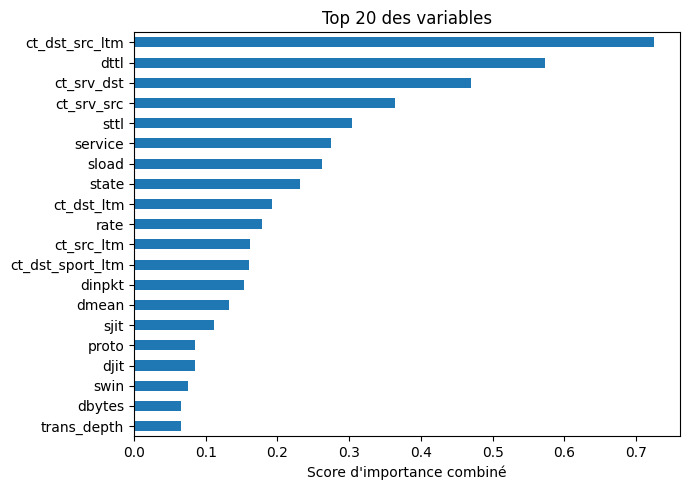


=== Jeux de variables ===
Toutes                         42 variables, 58 colonnes
Manuelle                       10 variables, 14 colonnes
Décorrélée (sans étiquettes)   37 variables, 53 colonnes
Top-8                           8 variables, 20 colonnes
Top-12                         12 variables, 24 colonnes
Top-20                         20 variables, 36 colonnes
Top-30                         30 variables, 46 colonnes
Top-12 : ['ct_dst_src_ltm', 'dttl', 'ct_srv_dst', 'ct_srv_src', 'sttl', 'service', 'sload', 'state', 'ct_dst_ltm', 'ct_src_ltm', 'ct_dst_sport_ltm', 'dinpkt']
Variables retirées par la décorrélation : ['ct_ftp_cmd', 'dmean', 'dtcpb', 'dwin', 'sload']


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

RUN_OCSVM_FS = False        # True : ajoute le One-Class SVM (plusieurs minutes de plus)
MANUAL = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "proto", "ct_srv_src", "ct_dst_ltm", "ct_src_ltm", "ct_srv_dst"]

def base_of(n):
    for p in ("proto", "service", "state"):
        if n.startswith(p + "_"): return p
    return n
base_cols = np.array([base_of(n) for n in noms_var])
bases = [str(b) for b in dict.fromkeys(base_cols)]
col_idx = {b: np.where(base_cols == b)[0] for b in bases}
print(f"{Xtr.shape[1]} colonnes pour {len(bases)} variables d'origine")

# ---- 1. séparabilité univariée (validation) ----
uni = {}
for b in bases:
    v = []
    for j in col_idx[b]:
        x = np.abs(Xva[:, j]) if is_num[j] else Xva[:, j]
        if x.std() == 0: v.append(0.0); continue
        a = roc_auc_score(yva, x)
        v.append(max(a - 0.5, 0) * 2 if is_num[j] else abs(a - 0.5) * 2)
    uni[b] = max(v)

# ---- 2. importance par permutation (validation coupée en deux) ----
perm_order = np.random.default_rng(SEED).permutation(len(Xva))
A, B = perm_order[: len(Xva) // 2], perm_order[len(Xva) // 2:]
rf = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEED, n_jobs=-1).fit(Xva[A], yva[A])
pi = permutation_importance(rf, Xva[B], yva[B], scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
perm = {b: float(np.clip(pi.importances_mean[col_idx[b]], 0, None).sum()) for b in bases}

def norm(d):
    m = max(d.values()) or 1.0
    return {k: v / m for k, v in d.items()}
un, pn = norm(uni), norm(perm)
score = {b: 0.5 * un[b] + 0.5 * pn[b] for b in bases}
order_rank = sorted(bases, key=lambda b: -score[b])

imp = pd.DataFrame({"separabilite": uni, "permutation": perm, "score": score}).loc[order_rank].round(3)
print("\n=== Importance des variables (top 20) ===\n" + imp.head(20).to_string())
plt.figure(figsize=(7, 5)); imp.head(20)["score"][::-1].plot.barh(); plt.xlabel("Score d'importance combiné"); plt.title("Top 20 des variables"); plt.tight_layout(); plt.show()

# ---- 3. redondance : corrélation sur l'entraînement ----
num_bases = [b for b in bases if is_num[col_idx[b][0]]]
C = pd.DataFrame(np.corrcoef(Xtr[:, [col_idx[b][0] for b in num_bases]].T), index=num_bases, columns=num_bases)
def decorrelate(order, seuil=0.95):
    kept = []
    for b in order:
        if b in num_bases and any(k in num_bases and abs(C.loc[b, k]) > seuil for k in kept): continue
        kept.append(b)
    return kept
order_dec = decorrelate(order_rank)

sets = {"Toutes": bases,
        "Manuelle": [b for b in MANUAL if b in bases],
        "Décorrélée (sans étiquettes)": decorrelate(bases)}
for k in (8, 12, 20, 30):
    sets[f"Top-{k}"] = order_dec[:k]
cols_of = {n: np.sort(np.concatenate([col_idx[b] for b in v])) for n, v in sets.items()}
print("\n=== Jeux de variables ===")
for n in sets: print(f"{n:30s} {len(sets[n]):2d} variables, {len(cols_of[n]):2d} colonnes")
print("Top-12 :", order_dec[:12])
print("Variables retirées par la décorrélation :", sorted(set(bases) - set(decorrelate(bases))))

=== PR-AUC VALIDATION (hasard 0.658) ===
                  Toutes  Manuelle  Décorrélée (sans étiquettes)  Top-8  Top-12  Top-20  Top-30
Mahalanobis        0.853     0.709                         0.854  0.797   0.809   0.842   0.848
Isolation Forest   0.867     0.785                         0.859  0.893   0.867   0.873   0.874
kNN                0.942     0.851                         0.942  0.905   0.901   0.932   0.941

Jeu Top-k choisi sur la validation (PR-AUC moyenne) : Top-30


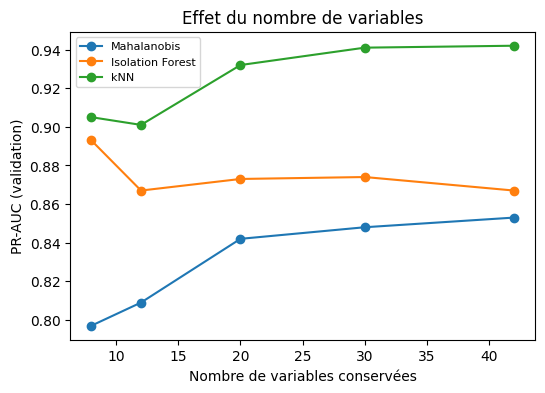

In [17]:
# ---- Évaluation sur la VALIDATION (sert à choisir k) ----
dets = ["Mahalanobis", "Isolation Forest", "kNN"] + (["One-Class SVM"] if RUN_OCSVM_FS else [])
n_all = Xtr.shape[1]
FS_models, FS_val, FS_fit = {}, {}, {}
for sname, cols in cols_of.items():
    for nom in dets:
        p = dict(PARAMS[nom])
        if nom == "One-Class SVM": p["gamma"] = p["gamma"] * n_all / len(cols)
        t = time.time(); f = build(nom, Xtr[:, cols], {nom: p}); FS_fit[(nom, sname)] = time.time() - t
        FS_models[(nom, sname)] = f
        FS_val[(nom, sname)] = f(Xva[:, cols])

tab_val = pd.DataFrame({sname: {nom: round(average_precision_score(yva, FS_val[(nom, sname)]), 3) for nom in dets} for sname in cols_of})
print(f"=== PR-AUC VALIDATION (hasard {yva.mean():.3f}) ===\n" + tab_val.to_string())

ks = [n for n in cols_of if n.startswith("Top-")]
k_best = max(ks, key=lambda n: tab_val.loc[dets, n].mean())
print(f"\nJeu Top-k choisi sur la validation (PR-AUC moyenne) : {k_best}")
plt.figure(figsize=(6, 4))
for nom in dets: plt.plot([len(sets[n]) for n in ks] + [len(bases)], [tab_val.loc[nom, n] for n in ks] + [tab_val.loc[nom, "Toutes"]], marker="o", label=nom)
plt.xlabel("Nombre de variables conservées"); plt.ylabel("PR-AUC (validation)"); plt.legend(fontsize=8); plt.title("Effet du nombre de variables"); plt.show()

In [18]:
# ---- Comparaison finale sur le TEST (une seule fois, analyse supplémentaire) ----
finaux = ["Toutes", "Manuelle", "Décorrélée (sans étiquettes)", k_best]
lignes = []
for sname in finaux:
    cols = cols_of[sname]
    for nom in dets:
        f = FS_models[(nom, sname)]
        t = time.time(); s = f(Xte[:, cols]); ts = time.time() - t
        seuil = np.quantile(FS_val[(nom, sname)][normal_va], 0.95)       # seuil fixé sur le normal de validation
        pred = (s > seuil).astype(int)
        lignes.append(dict(jeu=sname, nb_colonnes=len(cols), detecteur=nom,
                           PR_AUC=round(average_precision_score(yte, s), 3), FP_observe=round(pred[normal_te].mean(), 3),
                           rappel=round(recall_score(yte, pred), 3), t_fit_s=round(FS_fit[(nom, sname)], 1),
                           ms_par_flux=round(ts / len(Xte) * 1000, 3)))
res_fs = pd.DataFrame(lignes)
print(f"=== TEST - sélection de variables (FP cible 5 %, hasard {yte.mean():.3f}) ===")
print(res_fs.to_string(index=False))
print("\nPR-AUC test par détecteur et par jeu :")
print(res_fs.pivot(index="detecteur", columns="jeu", values="PR_AUC")[finaux].to_string())
print(f"\nRéduction : {len(cols_of['Toutes'])} colonnes -> {len(cols_of[k_best])} ({k_best}) et {len(cols_of['Manuelle'])} (Manuelle)")

=== TEST - sélection de variables (FP cible 5 %, hasard 0.484) ===
                         jeu  nb_colonnes        detecteur  PR_AUC  FP_observe  rappel  t_fit_s  ms_par_flux
                      Toutes           58      Mahalanobis   0.680       0.064   0.232      0.0        0.002
                      Toutes           58 Isolation Forest   0.701       0.072   0.343      2.7        0.035
                      Toutes           58              kNN   0.739       0.147   0.480      0.0        0.201
                    Manuelle           14      Mahalanobis   0.537       0.047   0.126      0.0        0.000
                    Manuelle           14 Isolation Forest   0.578       0.063   0.167      2.6        0.045
                    Manuelle           14              kNN   0.617       0.100   0.255      0.0        0.023
Décorrélée (sans étiquettes)           53      Mahalanobis   0.678       0.065   0.234      0.0        0.002
Décorrélée (sans étiquettes)           53 Isolation Forest   

## Annexe B. Apprentissage d'ensemble : combiner les détecteurs

**Idée.** Un flux est jugé suspect par une décision collective plutôt que par un seul détecteur.

**Systèmes comparés** (fixés *avant* de regarder le test)
1. **Vote majoritaire 3/5** : Mahalanobis, Isolation Forest, One-Class SVM, DBSCAN, kNN (système demandé).
2. **Vote 2/3 sur trois familles distinctes** : Mahalanobis (statistique), Isolation Forest (arbres), kNN (voisinage). Raison : DBSCAN et kNN produisent ici les mêmes scores ; dans le vote 3/5 ils comptent donc pour deux voix identiques.
3. **Fusion de scores** : chaque score est converti en rang par rapport au trafic *normal de validation* (fonction de répartition empirique, valeur entre 0 et 1), puis on prend la moyenne des cinq. On obtient un score continu, donc une PR-AUC.

**Calibration sans étiquette d'attaque.** Un vote donne un taux de faux positifs qui dépend du seuil de chaque détecteur. Le seuil individuel commun *q* est donc ajusté pour que le **système complet** ait 5 % de faux positifs sur le trafic normal de validation. Le test n'intervient pas. Une version « naïve » (q = 95 % pour chacun) est montrée pour comparaison.

**Comparaison équitable.** Comme le taux de faux positifs observé sur le test diffère d'un système à l'autre, on compare aussi le rappel des détecteurs seuls **au même taux de faux positifs que le vote** (lu sur leur courbe ROC).

In [19]:
from sklearn.metrics import roc_curve

noms5 = ["Mahalanobis", "Isolation Forest", "One-Class SVM", "DBSCAN", "kNN"]
noms3 = ["Mahalanobis", "Isolation Forest", "kNN"]

def ecdf_ref(ref):
    r = np.sort(ref)
    return lambda s: np.searchsorted(r, s, side="right") / len(r)
U_va, U_te = {}, {}
for n in noms5:
    F = ecdf_ref(SV[n][normal_va])                 # rang par rapport au normal de validation
    U_va[n], U_te[n] = F(SV[n]), F(S_te[n])
U_vn = {n: U_va[n][normal_va] for n in noms5}

def votes(U, names, q): return sum((U[n] > q).astype(int) for n in names)
GRID = np.unique(np.concatenate([np.linspace(0.5, 0.99, 60), np.linspace(0.99, 0.9999, 80)]))
def calibrer(names, m, cible=0.05):
    fp = np.array([(votes(U_vn, names, q) >= m).mean() for q in GRID])
    return float(GRID[np.argmin(np.abs(fp - cible))])

def mesures(nom, pred, q=None, pred_va=None):
    return dict(systeme=nom, q_individuel=None if q is None else round(q, 3),
                FP_val=None if pred_va is None else round(pred_va[normal_va].mean(), 3),
                FP_test=round(pred[normal_te].mean(), 3), precision=round(precision_score(yte, pred, zero_division=0), 3),
                rappel=round(recall_score(yte, pred), 3), F1=round(f1_score(yte, pred, zero_division=0), 3))

lignes, P = [], {}
def systeme_vote(nom, names, m, q):
    pv = (votes(U_va, names, q) >= m).astype(int); pt = (votes(U_te, names, q) >= m).astype(int)
    P[nom] = pt; lignes.append(mesures(nom, pt, q, pv))

systeme_vote("Vote 3/5 naïf (q = 95 %)", noms5, 3, 0.95)
systeme_vote("Vote 3/5 calibré", noms5, 3, calibrer(noms5, 3))
systeme_vote("Vote 2/3 calibré (3 familles)", noms3, 2, calibrer(noms3, 2))

# fusion de scores : moyenne des rangs
fus_va = np.mean([U_va[n] for n in noms5], axis=0); fus_te = np.mean([U_te[n] for n in noms5], axis=0)
seuil_f = np.quantile(fus_va[normal_va], 0.95)
P["Fusion (moyenne des rangs)"] = (fus_te > seuil_f).astype(int)
lignes.append(mesures("Fusion (moyenne des rangs)", P["Fusion (moyenne des rangs)"], None, (fus_va > seuil_f).astype(int)))
for n in noms5:                                     # détecteurs seuls, seuil à 5 % sur le normal de validation
    lignes.append(mesures(f"Seul : {n}", preds5[n], None, (SV[n] > np.quantile(SV[n][normal_va], 0.95)).astype(int)))
print("=== ENSEMBLES vs détecteurs seuls (test) ===")
print(pd.DataFrame(lignes).to_string(index=False))

# PR-AUC (scores continus uniquement) et comparaison à FP identique
ref = "Vote 3/5 calibré"; fp_ref = P[ref][normal_te].mean()
print(f"\nPR-AUC test (hasard {yte.mean():.3f}) : fusion = {average_precision_score(yte, fus_te):.3f} | "
      + " | ".join(f"{n} = {average_precision_score(yte, S_te[n]):.3f}" for n in noms5))
print(f"\n=== Rappel des systèmes continus au MÊME taux de FP que '{ref}' (FP test = {fp_ref:.3f}) ===")
comp = {}
for n, s in list(S_te.items()) + [("Fusion", fus_te)]:
    fpr, tpr, _ = roc_curve(yte, s); comp[n] = round(float(np.interp(fp_ref, fpr, tpr)), 3)
comp[ref] = round(float(P[ref][~normal_te].mean()), 3)
print(pd.Series(comp).sort_values(ascending=False).to_string())

=== ENSEMBLES vs détecteurs seuls (test) ===
                      systeme  q_individuel  FP_val  FP_test  precision  rappel    F1
     Vote 3/5 naïf (q = 95 %)          0.95   0.044    0.138      0.762   0.471 0.582
             Vote 3/5 calibré          0.94   0.052    0.157      0.746   0.491 0.592
Vote 2/3 calibré (3 familles)          0.94   0.047    0.083      0.809   0.376 0.514
   Fusion (moyenne des rangs)           NaN   0.050    0.125      0.787   0.494 0.608
           Seul : Mahalanobis           NaN   0.050    0.064      0.772   0.232 0.357
      Seul : Isolation Forest           NaN   0.050    0.072      0.818   0.343 0.483
         Seul : One-Class SVM           NaN   0.050    0.165      0.740   0.499 0.596
                Seul : DBSCAN           NaN   0.050    0.148      0.753   0.479 0.586
                   Seul : kNN           NaN   0.050    0.147      0.753   0.480 0.586

PR-AUC test (hasard 0.484) : fusion = 0.738 | Mahalanobis = 0.680 | Isolation Forest = 0.701 |

=== Nombre de votes requis ===
           systeme  q_individuel FP_val  FP_test  precision  rappel    F1
au moins 1/5 votes         0.982   None    0.099      0.802   0.427 0.557
au moins 2/5 votes         0.965   None    0.125      0.771   0.449 0.567
au moins 3/5 votes         0.940   None    0.157      0.746   0.491 0.592
au moins 4/5 votes         0.882   None    0.115      0.798   0.484 0.603
au moins 5/5 votes         0.816   None    0.111      0.799   0.467 0.590

=== Corrélation des décisions entre détecteurs (test, q = 95 %) ===
                  Mahalanobis  Isolation Forest  One-Class SVM  DBSCAN   kNN
Mahalanobis              1.00              0.57           0.50    0.51  0.51
Isolation Forest         0.57              1.00           0.58    0.59  0.59
One-Class SVM            0.50              0.58           1.00    0.91  0.91
DBSCAN                   0.51              0.59           0.91    1.00  1.00
kNN                      0.51              0.59           0.91    1.00 

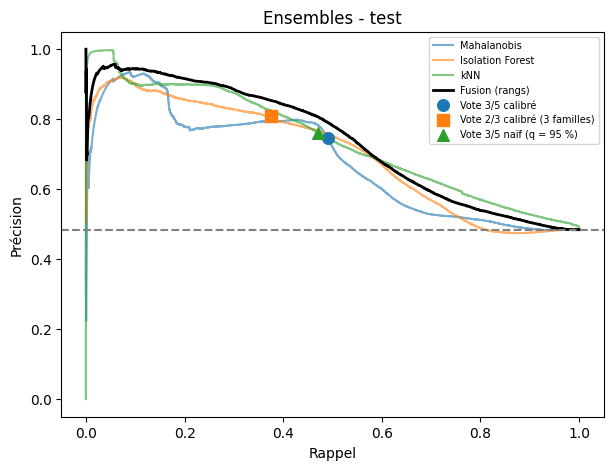

In [20]:
# Sensibilité au nombre de votes requis (5 détecteurs, calibration à 5 % de FP sur la validation)
rows = []
for m in range(1, 6):
    q = calibrer(noms5, m); pt = (votes(U_te, noms5, q) >= m).astype(int)
    rows.append(mesures(f"au moins {m}/5 votes", pt, q))
print("=== Nombre de votes requis ===\n" + pd.DataFrame(rows).to_string(index=False))

# Accord entre détecteurs (décisions à q = 95 %, test) : montre la redondance DBSCAN / kNN
dec = pd.DataFrame({n: (U_te[n] > 0.95).astype(int) for n in noms5})
print("\n=== Corrélation des décisions entre détecteurs (test, q = 95 %) ===\n" + dec.corr().round(2).to_string())

# Rappel par famille : vote vs fusion vs meilleurs détecteurs seuls
fam_e = pd.DataFrame({"Vote 3/5 calibré": P["Vote 3/5 calibré"], "Vote 2/3 calibré": P["Vote 2/3 calibré (3 familles)"],
                      "Fusion": P["Fusion (moyenne des rangs)"], "kNN seul": preds5["kNN"],
                      "Isolation Forest seul": preds5["Isolation Forest"], "famille": fam_te})
print("\n=== Rappel par famille d'attaque (test) ===")
print(fam_e[fam_e.famille != "Normal"].groupby("famille").mean().round(3).to_string())

# Graphique précision-rappel : scores continus + points de fonctionnement des systèmes
plt.figure(figsize=(7, 5))
for n in ["Mahalanobis", "Isolation Forest", "kNN"]:
    p, r, _ = precision_recall_curve(yte, S_te[n]); plt.plot(r, p, alpha=0.6, label=n)
p, r, _ = precision_recall_curve(yte, fus_te); plt.plot(r, p, "k", lw=2, label="Fusion (rangs)")
for nom, mk in [("Vote 3/5 calibré", "o"), ("Vote 2/3 calibré (3 familles)", "s"), ("Vote 3/5 naïf (q = 95 %)", "^")]:
    plt.scatter(recall_score(yte, P[nom]), precision_score(yte, P[nom]), marker=mk, s=70, zorder=5, label=nom)
plt.axhline(yte.mean(), ls="--", c="gray"); plt.xlabel("Rappel"); plt.ylabel("Précision")
plt.title("Ensembles - test"); plt.legend(fontsize=7); plt.show()

## Annexe C. Explicabilité : pourquoi ce flux est-il signalé ?

À exécuter **après l'annexe B** (elle réutilise ses variables).

**Une méthode adaptée à chaque détecteur** (une seule méthode ne convient pas à tous) :

| Détecteur | Méthode | Nature |
|---|---|---|
| Mahalanobis | Décomposition exacte de la distance² : contribution de la variable *j* = (x-μ)ⱼ · [Σ⁻¹(x-μ)]ⱼ | **exacte** (la somme redonne la distance) |
| kNN / DBSCAN | Décomposition exacte de la distance² au voisin normal le plus proche : (xⱼ - voisinⱼ)² | **exacte** |
| Isolation Forest, One-Class SVM | **Occlusion** : on remplace une variable par sa valeur normale (médiane) et on mesure la baisse du score | approchée, valable pour tout détecteur |
| Isolation Forest (option) | **SHAP** (TreeExplainer), si la bibliothèque `shap` est installée | approchée |

Les contributions sont regroupées par **variable d'origine** (les colonnes one-hot de `proto`, `service`, `state` sont regroupées).

**Vérifier que les explications sont bonnes, pas seulement les afficher :**
1. *Fidélité* : si l'on neutralise les 3 variables jugées les plus importantes, le score doit baisser **beaucoup plus** qu'en neutralisant 3 variables au hasard.
2. *Accord* entre méthodes : recouvrement des 5 variables principales (indice de Jaccard), comparé au hasard.
3. *Cohérence par famille d'attaque* : les variables mises en avant doivent avoir un sens réseau.

In [21]:
def base_of_x(n):
    for p in ("proto", "service", "state"):
        if n.startswith(p + "_"): return p
    return n
bcols = np.array([base_of_x(n) for n in noms_var])
bases_x = [str(b) for b in dict.fromkeys(bcols)]
cidx = {b: np.where(bcols == b)[0] for b in bases_x}
def to_base(M): return np.stack([M[:, cidx[b]].sum(axis=1) for b in bases_x], axis=1)
def norm_pos(M):
    M = np.clip(M, 0, None); sm = M.sum(axis=1, keepdims=True)
    return np.divide(M, sm, out=np.zeros_like(M), where=sm > 0)

# --- Mahalanobis : décomposition exacte de la distance au carré ---
mu_m, Pm = lw.location_, lw.precision_
def attr_maha(X):
    Dv = X.astype(float) - mu_m
    return to_base(Dv * (Dv @ Pm))
# --- kNN / DBSCAN : décomposition exacte de la distance² au voisin normal le plus proche ---
nn1 = NearestNeighbors(n_neighbors=1).fit(Xtr)
def attr_knn(X):
    d_, ix_ = nn1.kneighbors(X)
    return to_base((X.astype(float) - Xtr[ix_[:, 0]].astype(float)) ** 2)
# --- Occlusion (tout détecteur) : baisse du score quand la variable est remplacée par la valeur normale ---
ref_med = np.median(Xtr, axis=0)
def attr_occl(f, X):
    s0 = f(X); out = []
    for b in bases_x:
        Xm = X.copy(); Xm[:, cidx[b]] = ref_med[cidx[b]]
        out.append(s0 - f(Xm))
    return np.stack(out, axis=1)

# Vérification : la somme des contributions doit redonner la distance
Xchk = Xte[:200]
e1 = np.abs(attr_maha(Xchk).sum(1) - lw.mahalanobis(Xchk)).max()
e2 = np.abs(attr_knn(Xchk).sum(1) - nn1.kneighbors(Xchk)[0][:, 0] ** 2).max()
print(f"Vérification de l'exactitude - Mahalanobis : écart max {e1:.2e} | kNN : écart max {e2:.2e}")

Vérification de l'exactitude - Mahalanobis : écart max 5.60e-12 | kNN : écart max 3.31e-06


In [22]:
# Échantillon de flux d'attaque détectés par la fusion (au plus 40 par famille)
rng_x = np.random.default_rng(SEED)
det_true = np.where((fus_te > seuil_f) & (yte == 1))[0]
sel = []
for fa in np.unique(fam_te[det_true]):
    ii = det_true[fam_te[det_true] == fa]
    sel += list(rng_x.choice(ii, min(40, len(ii)), replace=False))
sel = np.array(sel); Xs_x = Xte[sel]; fam_s = fam_te[sel]
print(f"{len(sel)} flux d'attaque détectés, expliqués par chaque méthode")

f_maha = lambda Z: lw.mahalanobis(Z)
f_knn = lambda Z: nn1.kneighbors(Z)[0][:, 0]
f_if = build("Isolation Forest", Xtr)
AT = {"Mahalanobis (exacte)": attr_maha(Xs_x), "kNN (exacte)": attr_knn(Xs_x),
      "Isolation Forest (occlusion)": attr_occl(f_if, Xs_x)}
DETS = {"Mahalanobis (exacte)": (f_maha, "Mahalanobis"), "kNN (exacte)": (f_knn, "kNN"),
        "Isolation Forest (occlusion)": (f_if, "Isolation Forest")}

# 1. FIDÉLITÉ : baisse du score en neutralisant les 3 variables jugées les plus importantes vs 3 au hasard
def fidelite(nom, k=3, n_rand=10):
    f_, cle = DETS[nom]; Am = AT[nom]
    s0 = f_(Xs_x); den = np.maximum(s0 - np.median(SV[cle][normal_va]), 1e-9)
    def neutraliser(selb):
        Xm = Xs_x.copy()
        for i in range(len(Xm)):
            for bi in selb[i]: Xm[i, cidx[bases_x[bi]]] = ref_med[cidx[bases_x[bi]]]
        return np.clip((s0 - f_(Xm)) / den, -1, 1).mean()
    top = np.argsort(-Am, axis=1)[:, :k]
    d_top = neutraliser(top)
    d_rnd = np.mean([neutraliser(np.argsort(rng_x.random(Am.shape), axis=1)[:, :k]) for _ in range(n_rand)])
    return dict(methode=nom, baisse_top3=round(d_top, 3), baisse_3_au_hasard=round(d_rnd, 3),
                rapport=round(d_top / d_rnd, 1) if d_rnd > 1e-6 else None)
print("\n=== FIDÉLITÉ (part de l'excès de score au-dessus du normal qui disparaît) ===")
print(pd.DataFrame([fidelite(n) for n in AT]).to_string(index=False))

# 2. ACCORD entre méthodes : indice de Jaccard sur les 5 premières variables
def top5(M): return [set(r) for r in np.argsort(-M, axis=1)[:, :5]]
T5 = {n: top5(AT[n]) for n in AT}
jac = pd.DataFrame({b_: {a_: np.mean([len(x & y) / len(x | y) for x, y in zip(T5[a_], T5[b_])]) for a_ in AT} for b_ in AT}).round(2)
hasard = np.mean([len(x & y) / len(x | y) for x, y in zip(top5(rng_x.random(AT["kNN (exacte)"].shape)), top5(rng_x.random(AT["kNN (exacte)"].shape)))])
print(f"\n=== ACCORD entre méthodes (Jaccard des 5 variables principales ; hasard = {hasard:.2f}) ===\n" + jac.to_string())

# 3. VARIABLES LES PLUS EXPLICATIVES PAR FAMILLE (consensus Mahalanobis + kNN)
cons = 0.5 * (norm_pos(AT["Mahalanobis (exacte)"]) + norm_pos(AT["kNN (exacte)"]))
rows = []
for fa in sorted(np.unique(fam_s)):
    m_ = cons[fam_s == fa].mean(axis=0)
    rows.append(dict(famille=fa, nb_flux=int((fam_s == fa).sum()), variables_principales=", ".join(bases_x[j] for j in np.argsort(-m_)[:3])))
print("\n=== Variables les plus explicatives par famille d'attaque ===\n" + pd.DataFrame(rows).to_string(index=False))

360 flux d'attaque détectés, expliqués par chaque méthode

=== FIDÉLITÉ (part de l'excès de score au-dessus du normal qui disparaît) ===
                     methode  baisse_top3  baisse_3_au_hasard rapport
        Mahalanobis (exacte)       -0.664              -0.652    None
                kNN (exacte)        0.012              -0.353    None
Isolation Forest (occlusion)        0.593              -0.096    None

=== ACCORD entre méthodes (Jaccard des 5 variables principales ; hasard = 0.06) ===
                              Mahalanobis (exacte)  kNN (exacte)  Isolation Forest (occlusion)
Mahalanobis (exacte)                          1.00          0.15                          0.24
kNN (exacte)                                  0.15          1.00                          0.22
Isolation Forest (occlusion)                  0.24          0.22                          1.00

=== Variables les plus explicatives par famille d'attaque ===
       famille  nb_flux                  variables_prin

In [23]:
# (Option) SHAP pour Isolation Forest : nécessite `pip install shap` (dans Colab : !pip install shap dans une cellule séparée)
USE_SHAP = True
if USE_SHAP:
    try:
        import shap
        m_if = IsolationForest(random_state=SEED, n_jobs=-1, **PARAMS["Isolation Forest"]).fit(Xtr)
        sv_ = shap.TreeExplainer(m_if).shap_values(Xs_x)
        A_shap = to_base(-np.asarray(sv_))                      # valeurs SHAP négatives = vers l'anomalie
        T5s = top5(A_shap)
        for nom in ["Isolation Forest (occlusion)", "Mahalanobis (exacte)", "kNN (exacte)"]:
            print(f"Jaccard SHAP vs {nom:30s}: {np.mean([len(x & y) / len(x | y) for x, y in zip(T5s, T5[nom])]):.2f}")
        AT["Isolation Forest (SHAP)"] = A_shap; DETS["Isolation Forest (SHAP)"] = (f_if, "Isolation Forest")
        print(pd.DataFrame([fidelite("Isolation Forest (SHAP)")]).to_string(index=False))
    except ImportError:
        print("shap n'est pas installé : exécuter `!pip install shap` puis relancer cette cellule (le reste du notebook ne dépend pas de SHAP).")
    except Exception as e:
        print("SHAP non exécuté :", type(e).__name__, str(e)[:200])

Jaccard SHAP vs Isolation Forest (occlusion)  : 0.44
Jaccard SHAP vs Mahalanobis (exacte)          : 0.29
Jaccard SHAP vs kNN (exacte)                  : 0.23
                methode  baisse_top3  baisse_3_au_hasard rapport
Isolation Forest (SHAP)        0.485                -0.1    None


## Annexe D. Score de risque de 0 à 100

À exécuter après l'annexe C. Une **alerte** est un flux dont le score de fusion (annexe B) dépasse le seuil à 5 % de faux positifs sur la validation. Un flux sans alerte a un risque de 0. Pour une alerte :

**Risque = 100 × (0,45 · A + 0,30 · V + 0,25 · E)** (× un facteur de criticité si l'information existe)

| Composante | Définition | Valeur |
|---|---|---|
| **A** niveau d'anomalie | rareté du score de fusion par rapport au trafic normal de validation : −log₁₀(1 − rang) / 4, plafonné à 1 | 0 à 1 |
| **V** accord des détecteurs | nombre de détecteurs (sur 5) en alerte à q = 95 %, divisé par 5 | 0 à 1 |
| **E** importance des caractéristiques inhabituelles | extrémité (par rapport au trafic normal) de chaque variable, **pondérée par sa contribution à l'explication** | 0 à 1 |
| criticité de la machine | **non disponible** dans UNSW-NB15 (pas d'adresses IP dans ces fichiers) : paramètre `CRITICITE` prévu mais neutre ici | - |

Niveaux : 0-29 Faible, 30-59 Moyen, 60-79 Élevé, 80-100 Critique.

> **Les poids (0,45 / 0,30 / 0,25) sont un choix de conception fixé a priori, pas appris.** Ils ne sont pas ajustés sur le test. On vérifie ensuite que le score est *utile* : un analyste qui traite les alertes dans l'ordre du risque doit tomber plus souvent sur de vraies attaques.

In [24]:
CRITICITE = None        # vecteur (une valeur dans [0, 1] par flux du test) si une criticité machine est disponible
W_A, W_V, W_E = 0.45, 0.30, 0.25
NIVEAUX = [(0, 30, "Faible"), (30, 60, "Moyen"), (60, 80, "Élevé"), (80, 101, "Critique")]

ALERT = fus_te > seuil_f
idxA = np.where(ALERT)[0]
print(f"{len(idxA)} alertes sur {len(Xte)} flux ({ALERT.mean():.1%}) ; part de vraies attaques parmi elles : {yte[idxA].mean():.1%}")

# A : niveau d'anomalie
r_f = ecdf_ref(fus_va[normal_va])(fus_te)
comp_A = np.clip(-np.log10(np.maximum(1 - r_f, 1e-4)) / 4, 0, 1)
# V : accord des détecteurs
comp_V = np.sum([(U_te[n] > 0.95) for n in noms5], axis=0) / 5
# E : extrémité des variables inhabituelles, pondérée par leur contribution (consensus exact Mahalanobis + kNN)
Ac = 0.5 * (norm_pos(attr_maha(Xte[idxA])) + norm_pos(attr_knn(Xte[idxA])))
raw_sorted = {b: np.sort(train[b].values.astype(float)) for b in bases_x if b not in cat_cols}
raw_med = {b: float(np.median(train[b].values.astype(float))) for b in raw_sorted}
cat_freq = {b: train[b].value_counts(normalize=True) for b in cat_cols}
def pct_mid(b, v):
    a = raw_sorted[b]; return (np.searchsorted(a, v, side="left") + np.searchsorted(a, v, side="right")) / 2 / len(a)
PCT = np.zeros((len(idxA), len(bases_x))); EXT = np.zeros_like(PCT)
for j, b in enumerate(bases_x):
    if b in cat_cols:
        fr = test[b].iloc[idxA].map(cat_freq[b]).fillna(0).values
        PCT[:, j] = np.nan; EXT[:, j] = 1 - fr
    else:
        PCT[:, j] = pct_mid(b, test[b].values[idxA].astype(float)); EXT[:, j] = 2 * np.abs(PCT[:, j] - 0.5)
comp_E = np.zeros(len(Xte)); comp_E[idxA] = (Ac * EXT).sum(axis=1)

risk = np.zeros(len(Xte))
risk[idxA] = 100 * (W_A * comp_A[idxA] + W_V * comp_V[idxA] + W_E * comp_E[idxA])
if CRITICITE is not None: risk = risk * np.asarray(CRITICITE)
niveau = np.array(["Aucune alerte"] * len(Xte), dtype=object)
for lo, hi, nom in NIVEAUX: niveau[ALERT & (risk >= lo) & (risk < hi)] = nom

print("\nDistribution du score de risque parmi les alertes :", pd.Series(risk[idxA]).describe().round(1).to_dict())
rows = []
for lo, hi, nom in NIVEAUX:
    m_ = niveau == nom
    rows.append(dict(niveau=nom, plage=f"{lo}-{min(hi-1, 100)}", nb_alertes=int(m_.sum()),
                     part_des_alertes=round(m_.sum() / max(len(idxA), 1), 3),
                     part_vraies_attaques=round(yte[m_].mean(), 3) if m_.sum() else None,
                     part_des_attaques_totales_couvertes=round(m_[yte == 1].sum() / (yte == 1).sum(), 3)))
print("\n=== Niveaux de risque (test) ===\n" + pd.DataFrame(rows).to_string(index=False))

30375 alertes sur 99869 flux (30.4%) ; part de vraies attaques parmi elles : 78.7%

Distribution du score de risque parmi les alertes : {'count': 30375.0, 'mean': 63.7, 'std': 16.9, 'min': 21.8, '25%': 52.9, '50%': 62.9, '75%': 73.9, 'max': 99.5}

=== Niveaux de risque (test) ===
  niveau  plage  nb_alertes  part_des_alertes  part_vraies_attaques  part_des_attaques_totales_couvertes
  Faible   0-29         751             0.025                 0.892                                0.014
   Moyen  30-59       11400             0.375                 0.680                                0.160
   Élevé  60-79       13713             0.451                 0.822                                0.233
Critique 80-100        4511             0.149                 0.936                                0.087


=== Part de vraies attaques parmi les N premières alertes traitées ===
 N_alertes_traitees  ordre_par_risque  ordre_par_fusion  ordre_aleatoire
                100             0.990             0.680            0.787
                500             0.998             0.846            0.787
               1000             0.999             0.922            0.787
               5000             0.933             0.944            0.787
              30375             0.787             0.787            0.787

ROC-AUC (attaque vs fausse alerte, parmi les alertes) : risque = 0.640 | score de fusion seul = 0.709

=== Risque moyen des alertes par famille ===
                count  mean
famille                    
Generic          3483  90.6
Analysis          188  68.7
DoS              1973  65.4
Backdoor          181  64.5
Exploits        14210  61.9
Fuzzers          1909  60.7
Worms              87  59.0
Normal           6455  57.5
Shellcode          51  55.6
Reconnaissance   1838  50.3


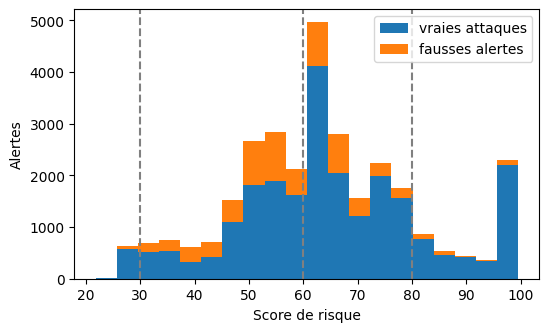

In [25]:
# Le score de risque est-il UTILE ? Précision en traitant les N premières alertes, par ordre de risque / de score de fusion / au hasard
ordre_risque = idxA[np.argsort(-risk[idxA], kind="stable")]
ordre_fusion = idxA[np.argsort(-fus_te[idxA], kind="stable")]
base_prec = yte[idxA].mean()
rows = []
for N in (100, 500, 1000, 5000, len(idxA)):
    N = min(N, len(idxA))
    rows.append(dict(N_alertes_traitees=N, ordre_par_risque=round(yte[ordre_risque[:N]].mean(), 3),
                     ordre_par_fusion=round(yte[ordre_fusion[:N]].mean(), 3), ordre_aleatoire=round(base_prec, 3)))
print("=== Part de vraies attaques parmi les N premières alertes traitées ===\n" + pd.DataFrame(rows).to_string(index=False))
print(f"\nROC-AUC (attaque vs fausse alerte, parmi les alertes) : risque = {roc_auc_score(yte[idxA], risk[idxA]):.3f}"
      f" | score de fusion seul = {roc_auc_score(yte[idxA], fus_te[idxA]):.3f}")

fa_df = pd.DataFrame({"famille": fam_te[idxA], "risque": risk[idxA]})
print("\n=== Risque moyen des alertes par famille ===\n" + fa_df.groupby("famille")["risque"].agg(["count", "mean"]).round(1).sort_values("mean", ascending=False).to_string())
plt.figure(figsize=(6, 3.5)); plt.hist([risk[idxA][yte[idxA] == 1], risk[idxA][yte[idxA] == 0]], bins=20, label=["vraies attaques", "fausses alertes"], stacked=True)
for x in (30, 60, 80): plt.axvline(x, c="gray", ls="--")
plt.xlabel("Score de risque"); plt.ylabel("Alertes"); plt.legend(); plt.show()

In [26]:
# ---------- Rapport d'anomalie complet (risque + votes + explication) ----------
LIB = {"dur": "durée de la connexion", "spkts": "nombre de paquets envoyés", "dpkts": "nombre de paquets reçus",
       "sbytes": "volume de données envoyé", "dbytes": "volume de données reçu", "rate": "débit (paquets/s)",
       "sttl": "TTL côté source", "dttl": "TTL côté destination", "sload": "charge côté source (bits/s)",
       "dload": "charge côté destination (bits/s)", "sloss": "paquets source retransmis ou perdus",
       "dloss": "paquets destination retransmis ou perdus", "sinpkt": "intervalle entre paquets envoyés",
       "dinpkt": "intervalle entre paquets reçus", "sjit": "gigue côté source", "djit": "gigue côté destination",
       "tcprtt": "temps aller-retour TCP", "smean": "taille moyenne des paquets envoyés", "dmean": "taille moyenne des paquets reçus",
       "trans_depth": "profondeur de transaction HTTP", "response_body_len": "taille du corps de réponse HTTP",
       "ct_srv_src": "connexions récentes vers le même service depuis la même source",
       "ct_srv_dst": "connexions récentes vers le même service vers la même destination",
       "ct_dst_ltm": "connexions récentes vers la même destination", "ct_src_ltm": "connexions récentes depuis la même source",
       "ct_state_ttl": "connexions récentes avec le même état/TTL", "proto": "protocole", "service": "service", "state": "état de la connexion"}
pos_in_alert = {int(f): k for k, f in enumerate(idxA)}

def rapport(i, verite=True):
    k = pos_in_alert[int(i)]
    top = np.argsort(-Ac[k])[:3]
    lignes_ = []
    en_combinaison = False
    for j in top:
        b = bases_x[j]; nom = f"{LIB[b]} ({b})" if b in LIB else b
        if b in cat_cols:
            lignes_.append(f"  - {nom} : '{test[b].iloc[i]}', rare dans le trafic normal ({cat_freq[b].get(test[b].iloc[i], 0):.1%} des flux)")
        else:
            v, pc, med = float(test[b].iloc[i]), PCT[k, j], raw_med[b]
            if pc >= 0.95: tag = "anormalement élevé"
            elif pc <= 0.05: tag = "anormalement faible"
            else: tag = "inhabituel en combinaison avec les autres variables"; en_combinaison = True
            lignes_.append(f"  - {nom} : {v:,.4g} ({tag} ; position {pc:.1%} dans le trafic normal ; valeur typique {med:,.4g})")
    votes_ = int(round(comp_V[i] * 5))
    txt = [f"Rapport d'anomalie - flux n°{i}",
           f"Niveau de risque : {risk[i]:.0f}/100 ({niveau[i]})  |  détecteurs en alerte : {votes_}/5  |  rareté du score : {r_f[i]:.4%} du trafic normal est moins suspect",
           "Caractéristiques inhabituelles :"] + lignes_
    expl = "Explication : cette connexion s'écarte du comportement normal surtout par " + ", ".join(LIB.get(bases_x[j], bases_x[j]) for j in top) + "."
    if en_combinaison: expl += " Certaines valeurs ne sont pas extrêmes isolément ; c'est leur combinaison qui est inhabituelle."
    txt.append(expl)
    if verite: txt.append(f"(Pour évaluation uniquement - vérité terrain : {fam_te[i]})")
    return "\n".join(txt)

tp = idxA[yte[idxA] == 1]; fp_ = idxA[yte[idxA] == 0]
exemples = [("ATTAQUE détectée, risque le plus élevé", tp[np.argmax(risk[tp])]),
            ("ATTAQUE détectée, risque médian", tp[np.argsort(risk[tp])[len(tp) // 2]]),
            ("ATTAQUE détectée, risque le plus faible", tp[np.argmin(risk[tp])])]
if len(fp_): exemples.append(("FAUSSE ALERTE au risque le plus élevé", fp_[np.argmax(risk[fp_])]))
for titre, i in exemples:
    print("=" * 100 + f"\n[{titre}]\n" + rapport(int(i)) + "\n")

[ATTAQUE détectée, risque le plus élevé]
Rapport d'anomalie - flux n°61356
Niveau de risque : 100/100 (Critique)  |  détecteurs en alerte : 5/5  |  rareté du score : 100.0000% du trafic normal est moins suspect
Caractéristiques inhabituelles :
  - temps aller-retour TCP (tcprtt) : 1.491 (anormalement élevé ; position 99.8% dans le trafic normal ; valeur typique 0.000719)
  - ackdat : 1.424 (anormalement élevé ; position 100.0% dans le trafic normal ; valeur typique 0.000151)
  - is_ftp_login : 1 (anormalement élevé ; position 99.5% dans le trafic normal ; valeur typique 0)
Explication : cette connexion s'écarte du comportement normal surtout par temps aller-retour TCP, ackdat, is_ftp_login.
(Pour évaluation uniquement - vérité terrain : Exploits)

[ATTAQUE détectée, risque médian]
Rapport d'anomalie - flux n°55774
Niveau de risque : 64/100 (Élevé)  |  détecteurs en alerte : 4/5  |  rareté du score : 99.0158% du trafic normal est moins suspect
Caractéristiques inhabituelles :
  - servic

## Annexe E. Évaluation complémentaire sur des attaques synthétiques (hors distribution)

Le fichier `UNSW_NB15_complementary_synthetic.csv` contient **500 flux synthétiques, tous des attaques**, répartis en 5 familles absentes d'UNSW-NB15 (Brute_Force, Web_Attack, Botnet, DDoS, Infiltration), avec les mêmes colonnes que le jeu d'origine.

**Il n'est pas fusionné avec le jeu principal.** Les raisons :
- il ne contient **aucun flux normal** : il ne peut donc pas servir à l'entraînement (qui exige du trafic normal), et ajouté à la validation ou au test il fausserait la proportion d'attaques et la comparaison avec les sections 5 à 9 ;
- ce sont des **données synthétiques** : leurs résultats ne prouvent rien sur la détection de vraies attaques.

**Utilisation** : test de **stress supplémentaire**, après figement de tout réglage. Les détecteurs sont ceux de la section 4 (hyperparamètres gelés) et les seuils sont ceux déjà fixés sur le normal de validation (FP cible 5 %). On mesure :
1. le **taux de détection par famille synthétique** (seul indicateur possible sans flux normaux) ;
2. un **test étendu** : flux normaux *réels* du test + attaques synthétiques (prévalence d'environ 1 %), avec PR-AUC et précision ;
3. un **diagnostic de cohérence** : dans un vrai flux, la taille moyenne des paquets (`smean`) vaut à peu près `sbytes / spkts`. Si les flux synthétiques ne respectent pas ces relations, les détecteurs peuvent les signaler à cause de combinaisons de valeurs impossibles et non à cause d'un comportement d'attaque.

In [27]:
COMP_PATH = DATA_DIR + "UNSW_NB15_complementary_synthetic.csv"      # à déposer dans projet6/data/

def evaluer_complementaire():
    comp = pd.read_csv(COMP_PATH)
    comp = comp.drop(columns=[c for c in ("id",) if c in comp.columns])           # colonne id vide
    manq = [c for c in feat if c not in comp.columns]
    assert not manq, f"colonnes absentes : {manq}"
    comp = comp.replace([np.inf, -np.inf], np.nan).dropna(subset=feat).reset_index(drop=True)
    Xc, famc = prep(comp), comp["attack_cat"].astype(str).values       # prétraitement appris sur l'entraînement uniquement
    print(f"{len(comp)} flux synthétiques ; familles : {pd.Series(famc).value_counts().to_dict()}")

    # ---- 1. Diagnostic de cohérence (à lire AVANT les résultats) ----
    def incoherence(df):
        r = (df.smean - df.sbytes / df.spkts.clip(lower=1)).abs() / df.smean.clip(lower=1)
        return float(r.median())
    print("\n=== Diagnostic de cohérence interne ===")
    print(f"Erreur relative médiane |smean - sbytes/spkts| / smean : réel (test) = {incoherence(test):.3f} | synthétique = {incoherence(comp):.3f}")
    print(f"Corrélation spkts / sbytes : réel (test) = {test.spkts.corr(test.sbytes):.3f} | synthétique = {comp.spkts.corr(comp.sbytes):.3f}")
    att_reel = test[test["label"] == 1]
    for col in ("sttl", "dttl", "proto", "service", "state"):
        vus = set(train[col].unique())
        print(f"Part de flux avec une valeur de {col} jamais vue dans le normal d'entraînement : "
              f"attaques réelles du test = {(~att_reel[col].isin(vus)).mean():.2f} | synthétique = {(~comp[col].isin(vus)).mean():.2f}")

    # ---- 2. Détection par famille synthétique (seuils déjà fixés, FP cible 5 %) ----
    sc, seuils = {}, {}
    for nom in noms:
        sc[nom] = build(nom, Xtr)(Xc)
        seuils[nom] = np.quantile(SV[nom][normal_va], 0.95)
    tab = pd.DataFrame({nom: pd.Series(sc[nom] > seuils[nom]).groupby(famc).mean() for nom in noms}).round(3)
    tab.insert(0, "nb_flux", pd.Series(famc).value_counts())
    tab.loc["TOUTES"] = [len(comp)] + [round(float((sc[nom] > seuils[nom]).mean()), 3) for nom in noms]
    tab.loc["Référence : attaques réelles du test"] = [int((~normal_te).sum())] + [round(float(preds5[nom][~normal_te].mean()), 3) for nom in noms]
    print("\n=== Taux de détection (rappel) à FP cible 5 % ===\n" + tab.to_string())

    # ---- 3. Test étendu : normal réel du test + attaques synthétiques ----
    n_norm = int(normal_te.sum()); prev = len(comp) / (n_norm + len(comp))
    rows = []
    for nom in noms:
        s_all = np.r_[S_te[nom][normal_te], sc[nom]]; y_all = np.r_[np.zeros(n_norm), np.ones(len(comp))]
        tp, fp = int((sc[nom] > seuils[nom]).sum()), int((S_te[nom][normal_te] > seuils[nom]).sum())
        rows.append(dict(detecteur=nom, PR_AUC=round(average_precision_score(y_all, s_all), 3), hasard=round(prev, 4),
                         rappel=round(tp / len(comp), 3), FP_test_reel=round(fp / n_norm, 3),
                         precision=round(tp / (tp + fp), 3) if (tp + fp) else None))
    print(f"\n=== Test étendu : {n_norm} flux normaux réels + {len(comp)} attaques synthétiques (prévalence {prev:.2%}) ===")
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nÀ interpréter avec prudence : données synthétiques, familles absentes du jeu d'origine, voir le diagnostic de cohérence.")

if os.path.exists(COMP_PATH):
    evaluer_complementaire()
else:
    print(f"Fichier absent : déposer UNSW_NB15_complementary_synthetic.csv dans {DATA_DIR} puis relancer cette cellule.")

Fichier absent : déposer UNSW_NB15_complementary_synthetic.csv dans /content/drive/MyDrive/projet6/data/ puis relancer cette cellule.
